# NIVELL 1 EXERCICI 1 Exploració inicial del dataset

**NIVELL 1**

**EXERCICI 1 EDA estructurat i neteja bàsica**

En aquest exercici has de realitzar una exploració inicial del DataFrame (sprint8_complex.xlsx) per respondre, com a mínim, a les següents preguntes:

Damos acceso a drive, informamos de la ruta donde tenemos ubicado el archivo:

In [1767]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [1768]:
from google.colab import drive
drive.mount ("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [1769]:
ruta = ("/content/drive/MyDrive/Colab Notebooks/sprint8_complex.xlsx")

Importamos pandas y convertimos en DataFrame el archivo:

#copia

In [1770]:
df_complex_original = pd.read_excel(ruta)


In [1771]:
#Trabajaremos con una copia del original:

df_complex = df_complex_original
df_complex.head()

,Dades de l'enquesta de treballadors 2025,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19
0,Generades aleatòriament per seguretat,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
3,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
4,1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7


In [1772]:
#Corregimos la cabecera para que empiece a leer datos en al fila 3:

df_complex = pd.read_excel(ruta, header=3)
df_complex.head()

,Unnamed: 0,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
2,2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
3,3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
4,4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1


» **Quantes files i columnes té el dataset?**

In [1773]:
df_complex.shape

(1007, 20)

L'arxiu te 1007 files i 20 columnes

» **Quin tipus de dades conté cada columna?**



In [1774]:
df_complex.dtypes

,0
Unnamed: 0,int64
Nom,object
Cognoms,object
DNI,object
País d'origen,object
Ciutat,object
Dia de Naixement,float64
Mes de Naixement,float64
Any de Naixement,float64
Gènere,object


Con el dtype podemos observar qué tipo de columna tenemos en el df_complex, las columnas object nos indican que en algunos caso puede haber dígitos o letras y eso ya nos da pistas que tendremos que cambiar el tipo de dato para que el valor sea más coerente.

**» Hi ha files duplicades?**

In [1775]:
cols = df_complex.columns[1:]
print(df_complex.duplicated(subset=cols).sum())

4


Para comprobar si tenemos filas duplicadas ignoramos la primera columna porque es un contador y por tanto nos distorsionaria los datos.

Cuando no tenemos en cuenta la primera columnas y sumamos las duplicadas el resultado que nos devuelve es de 4 filas

**» Les dades semblen coherents a primera vista?**

In [1776]:
df_complex.sample(10, random_state=42)

,Unnamed: 0,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
927,927,Anna,PÃ©rez Serra,81260169S,Espanya,Barcelona,11.0,2.0,1983.0,H,1.927 â‚¬,True,NaN,Grup B,Senior analyst,3.0,NaN,NaN,NaN,16.6
630,630,VÃ­ctor,DomÃ¨nech,22730042T,Espanya,Zaragoza,7.0,3.0,1995.0,H,"1,579 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,0.0,NaN,NaN,NaN,11.8
682,682,Carmen,DÃ­az Casals,89650979N,Espanya,Murcia,11.0,10.0,1968.0,H,"2,425 â‚¬",NaN,True,Grup C,Analista junior,0.0,NaN,NaN,NaN,21.1
514,514,VÃ­ctor,Roca MuÃ±oz,25081699D,Espanya,Palma,8.0,2.0,1976.0,D,943â‚¬,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,17.3
365,365,LucÃ­a,DomÃ¨nech,84449447A,Espanya,Zaragoza,1.0,6.0,1962.0,D,966 â‚¬,NaN,True,Grup A,Data Analyst,0.0,True,72237.0,10.8,15.4
655,655,VÃ­ctor,Serra,91229370H,Espanya,Palma,5.0,3.0,1968.0,D,"1,557 â‚¬",NaN,True,Grup B,Analista,NaN,True,29434.0,0.5,15.7
656,656,Felix,Richter,31742644W,Alemanya,Stuttgart,1.0,2.0,1966.0,H,tres mil,NaN,NaN,Grup A,Data Analyst,NaN,NaN,NaN,NaN,7.7
529,529,Alba,HernÃ¡ndez,43626780K,Espanya,Valladolid,16.0,8.0,1993.0,H,"1,664 â‚¬",True,NaN,Grup B,Analista junior,3.0,NaN,NaN,NaN,10.2
321,321,Ben,Koch,90293348E,Alemanya,Berlin,31.0,10.0,1980.0,F,"1,024 â‚¬",True,NaN,Grup A,Analista,3.0,NaN,NaN,NaN,9.0
70,70,Ã‰lise,Michel Garcia,57319709L,FranÃ§a,Nice,28.0,12.0,1960.0,D,1394â‚¬,True,NaN,Grup B,TÃ¨cnic IT,2.0,True,39561.0,NaN,16.5


Incoherencias a primera vista:

1. **Acentos y símbolos mal codificados.** Aparecen textos como `VÃ­ctor`, `FranÃ§a` y `TÃ¨cnic IT`. También pasa en la cabecera `Càrrec` y en el símbolo `€` de los salarios.
2. **`Unnamed: 0` repite el índice.** En todas las filas visibles, esa columna tiene el mismo número que aparece a la izquierda. Parece un índice guardado como columna.
3. **`Gènere` mezcla los códigos `H`, `D` y `F`.** Si `D` y `F` representan la misma categoría, habría que unificarlos. Para comprobarlo, hay que mirar cómo se definieron esos códigos.
4. **`Salari mensual` tiene formatos mezclados.** Hay valores como `1.927`, `1,579`, `943` y `tres mil`. Antes de convertirlos a números, hay que comprobar qué significan el punto y la coma.
5. **`Fills`, `No Fills` y `Nombre_fills` dan información redundante o incompleta.** En la fila **655**, `No Fills` es `True` pero `Nombre_fills` está vacío. En la **656** faltan los tres datos. Además, **`0.0` y `NaN` significan cosas distintas**: cero hijos y dato ausente, respectivamente.
6. **`Te_cotxe` muestra `True` y `NaN` en las filas visibles.** Hay que comprobar si esos `NaN` significan «no tiene coche» o «no consta». En la fila **70** sí consta que tiene coche y hay kilometraje, pero falta el consumo.
7. **Hay valores de coche que merece la pena comprobar.** En la fila **655** aparece un consumo de **0,5 L/100 km** y en la **365**, un kilometraje de **72.237 km anuales**. Son valores llamativos y conviene verificar las unidades o el dato original.
8. **Los días, meses, años y números de hijos aparecen como `11.0`, `1983.0` o `3.0`.** Son cantidades enteras que pandas está mostrando como decimales. Es un tema de **tipo de dato** más que de contenido.



**» Detectes possibles problemes o inconsistències evidents?**

In [1777]:
df_complex.describe()

,Unnamed: 0,Dia de Naixement,Mes de Naixement,Any de Naixement,Nombre_fills,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
count,1007.000000,1006.000000,1006.000000,1006.000000,709.000000,315.000000,261.000000,936.000000
mean,503.000000,15.027833,8.556660,2002.229622,1.203103,55951.050794,11.024521,15.379167
std,290.840162,10.327436,14.298532,143.118077,1.389404,62095.437005,8.775557,7.276425
min,0.000000,-99.000000,0.000000,1940.000000,0.000000,-50.000000,0.500000,-10.000000
25%,251.500000,7.000000,3.250000,1969.000000,0.000000,22632.000000,4.700000,12.800000
50%,503.000000,15.000000,6.000000,1982.000000,1.000000,56135.000000,9.800000,15.500000
75%,754.500000,24.000000,10.000000,1995.000000,2.000000,80000.000000,13.600000,18.300000
max,1006.000000,32.000000,99.000000,3000.000000,5.000000,1000000.000000,25.000000,42.000000


Con el método `describe` vemos estas incoherencias:

- Dia de Naixement: mínimo -99 y máximo 32. Un día va de 1 a 31.
- Mes de Naixement: mínimo 0 y máximo 99. Un mes va de 1 a 12.
- Any de Naixement: máximo 3000. Es un año futuro imposible.
- Km_anuals: mínimo -50 y máximo 1.000.000. No hay kilómetros negativos, y un millón al año es un valor extremo.
- Consum_mitja_L_100km: mínimo 0,5. Es un consumo casi imposible para un coche.

# NIVELL 1 EXERCICI 2  Validacions bàsiques de les dades i decisions d'eliminació




**EXERCICI 2 Validacions bàsiques de les dades i decisions d'eliminació**

Objectiu: assegurar que les dades compleixen unes condicions mínimes de qualitat i determinar quines files poden continuar sent analitzades i quines s'han de descartar.

En aquest exercici hauràs de validar aspectes clau del dataset que són crítics en qualsevol context real d'anàlisi de dades, prenent decisions justificades sobre la validesa o eliminació de registres.



# Exercici 2 Duplicados

**Existeixen identificadors únics (DNI) per a cada persona?**

In [1778]:
#primero ordeno por dni el df para que la visión de los DNI repetidos sean más fácil

df_complex_ordenado = df_complex.sort_values(by="DNI")

In [1779]:
#Guardo en una variable los datos duplicados:

df_complex_duplicado = df_complex_ordenado[df_complex_ordenado.duplicated(subset="DNI", keep=False)]

df_complex_duplicado

,Unnamed: 0,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
604,604,Laia,Navarro,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,"1,676 â‚¬",True,False,Grup A,Analista,1.0,True,50.0,NaN,14.2
250,250,Laia,Navarro Vila,15909601K,Espanya,Bilbao,30.0,5.0,1958.0,D,1235 euros,True,True,Grup D,Analista junior,0.0,False,NaN,NaN,10.3
759,759,Oriol,GÃ³mez,16618423V,Espanya,Sevilla,10.0,1.0,1968.0,NaN,"2,000 â‚¬",NaN,NaN,Grup A,Responsable de vendes,5.0,NaN,NaN,NaN,20.7
754,754,Oriol,GÃ³mez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 â‚¬,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN
654,654,Oriol,GÃ³mez,16618423V,Espanya,Madrid,10.0,1.0,1968.0,Home,1731 euros,True,NaN,Grup B,Data analyst,4.0,NaN,NaN,NaN,NaN
758,758,Oriol,GÃ³mez,16618423V,Espanya,MÃ laga,10.0,1.0,1968.0,H,1879 euros,True,NaN,Grup B,Data Analyst,4.0,False,NaN,NaN,NaN
558,558,Alexia,PÃ©rez DÃ­az,49529438G,Espanya,MÃ laga,12.0,10.0,1981.0,Dona,"1,176 â‚¬",NaN,True,Grup A,Data Analyst,0.0,False,NaN,NaN,38.0
692,692,Alexia,PÃ©rez DÃ­az,49529438G,Espanya,MÃ laga,12.0,10.0,1981.0,Dona,1663â‚¬,NaN,True,Grup C,Cap de projecte,NaN,True,80000.0,10.7,16.9
757,757,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9
1004,1004,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9


In [1780]:
#Miro si dentro de los DNI duplicados, el resto de datos también son iguales ignorando la primera columna que es el índice y cambia en todas:
df_complex_duplicado.drop(columns=df_complex_duplicado.columns[0]).duplicated(keep=False).sum()


np.int64(8)

In [1781]:
#El código anterior nos dice que hay ocho filas duplicadas exactas, vamos a comprobar cuáles son:

analisi = df_complex_duplicado.drop(columns=df_complex_duplicado.columns[0]).duplicated(keep=False)
df_complex_duplicado[analisi]

,Unnamed: 0,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
757,757,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9
1004,1004,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9
36,464,Ida,Karlsen Eriksen,55283701C,Noruega,Oslo,2.0,9.0,1992.0,D,"1,614 â‚¬",True,NaN,Grup B,Analista,3.0,NaN,NaN,NaN,10.6
40,1001,Ida,Karlsen Eriksen,55283701C,Noruega,Oslo,2.0,9.0,1992.0,D,"1,614 â‚¬",True,NaN,Grup B,Analista,3.0,NaN,NaN,NaN,10.6
1003,1003,Claudia,Gil Ferrer,55297384F,Espanya,ValÃ¨ncia,1.0,11.0,1981.0,H,1.789 â‚¬,NaN,True,Grup B,Responsable de vendes,0.0,True,29952.0,9.2,20.3
730,730,Claudia,Gil Ferrer,55297384F,Espanya,ValÃ¨ncia,1.0,11.0,1981.0,H,1.789 â‚¬,NaN,True,Grup B,Responsable de vendes,0.0,True,29952.0,9.2,20.3
1002,1002,Alba,MuÃ±oz,97954019T,Espanya,Bilbao,25.0,10.0,1983.0,D,"1,409 â‚¬",NaN,True,Grup B,Responsable de vendes,0.0,NaN,NaN,NaN,14.7
372,372,Alba,MuÃ±oz,97954019T,Espanya,Bilbao,25.0,10.0,1983.0,D,"1,409 â‚¬",NaN,True,Grup B,Responsable de vendes,0.0,NaN,NaN,NaN,14.7


Tras analizar las filas repetidas, detecto 8 registros que forman 4 parejas de duplicados exactos. Para compararlos he excluido la primera columna, que es un identificador que cambia en cada fila y haría que ninguna pareja coincidiera, y en todas las demás columnas los valores son idénticos.

**Què faràs amb les files duplicades o registres repetits?**

Eliminaré 4 registros, conservando el primero de cada pareja, para que una misma persona no cuente dos veces y no se distorsionen los recuentos ni las estadísticas.

El esto de registros duplicados después de eliminar los duplicados exactos, los conservo porque contienen información diferente. Es posible que correspondan a distintos puestos o lugares de trabajo de una misma persona. Con los datos disponibles, no puedo confirmarlo ni determinar qué registro debería prevalecer. Haré una consulta con el responsable de los datos para saber si prevalencen todos o no.

In [1782]:
#Borramos los registros exactos repetidos por posición y comprobamos el total de filas para saber qué se han eliminado exactamene 4 filas:

antes = len(df_complex)

df_complex = df_complex.drop(index=[1004, 40, 1003, 1002])

despues = len(df_complex)
print(f"Filas borradas: {antes - despues}")

Filas borradas: 4


Se han borrado exactamente las 4 filas que queríamos

# Exercici 2 Datos faltantes e incoherentes

**Hi ha valors obligatoris que falten o informació incoherent?**
 **Detectes formats incorrectes, errors de codificació o valors impossibles?**

In [1783]:
#Eliminamos la columna unnamed porque no aporta nada al DF y renumeramos el índice:

df_complex = df_complex.drop(columns=["Unnamed: 0"])


In [1784]:
#Miramos si hay registros que no tengan ni un valor:

df_complex.isnull().all(axis=1).sum()

np.int64(1)

In [1785]:
#En el código anterior solo nos sale un registro con todas las columnas nulas, vamos a buscar su índice para comprobarlo y eliminarlo:

df_complex[df_complex.isnull().all(axis=1)].index

Index([1005], dtype='int64')

In [1786]:
#Comprobamos:
df_complex.loc[1005]

,1005
Nom,NaN
Cognoms,NaN
DNI,NaN
País d'origen,NaN
Ciutat,NaN
Dia de Naixement,NaN
Mes de Naixement,NaN
Any de Naixement,NaN
Gènere,NaN
Salari mensual,NaN


In [1787]:
#Eliminamos:

df_complex = df_complex.drop(index=1005)

Detecto un registro que tiene todos los valores nulos y la elimino porque no puede aportarnos nada a nuestro estudio

In [1788]:
# Comprobamos cuántos registros tienen nulos en columnas relevantes:

df_complex[["Nom", "Cognoms", "DNI", "Ciutat", "Dia de Naixement", "Mes de Naixement", "Any de Naixement","Gènere","Grup Professional", "CÃ rrec"]]. isna().sum()

,0
Nom,0
Cognoms,0
DNI,0
Ciutat,0
Dia de Naixement,0
Mes de Naixement,0
Any de Naixement,0
Gènere,40
Grup Professional,1
CÃ rrec,1


In [1789]:
#Miramos qué filas son:

df_complex[df_complex[["Nom", "Cognoms", "DNI", "Ciutat", "Dia de Naixement", "Mes de Naixement", "Any de Naixement","Gènere","Grup Professional", "CÃ rrec"]].isna().any(axis =1)]

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
61,Xavier,MuÃ±oz Roca,21370793D,Espanya,ValÃ¨ncia,20.0,3.0,1983.0,NaN,3016â‚¬,NaN,True,Grup D,TÃ¨cnic IT,0.0,False,NaN,NaN,15.1
91,Alexia,Gil,89968863W,Espanya,Palma,25.0,11.0,1973.0,NaN,2.257 â‚¬,True,NaN,Grup C,Responsable de vendes,1.0,True,80000.0,11.5,17.7
102,Noa,Ruiz PÃ©rez,18113477L,Espanya,Murcia,12.0,8.0,1990.0,NaN,"2,627 â‚¬",True,NaN,Grup D,Responsable de vendes,1.0,False,NaN,NaN,22.2
109,Katharina,Braun Fischer,93240786N,Alemanya,Leipzig,11.0,7.0,1958.0,NaN,mil vuit-cents,True,NaN,Grup B,Administratiu,1.0,True,76180.0,NaN,9.1
126,Lucas,Petit,17324144F,FranÃ§a,Paris,21.0,5.0,1983.0,NaN,2227â‚¬,True,NaN,Grup C,Responsable de vendes,1.0,False,NaN,NaN,12.6
136,Marco,Rossi Ricci,94597104C,ItÃ lia,Torino,22.0,6.0,1983.0,NaN,771 â‚¬,True,NaN,Grup A,Analista junior,4.0,True,23728.0,25.0,12.5
221,Chiara,Esposito,62156850K,ItÃ lia,Roma,27.0,11.0,1994.0,NaN,"1,893 â‚¬",True,True,Grup B,Responsable de vendes,1.0,True,80000.0,25.0,15.1
255,VÃ­ctor,Moreno,87066247S,Espanya,A CoruÃ±a,3.0,11.0,2000.0,NaN,940 â‚¬,NaN,True,Grup A,Analista junior,0.0,False,NaN,NaN,13.0
286,Xavier,PÃ©rez,35375292W,Espanya,Las Palmas de Gran Canaria,10.0,1.0,1999.0,NaN,871â‚¬,True,NaN,Grup A,Analista,3.0,False,NaN,NaN,18.8
300,LucÃ­a,DomÃ¨nech Ãlvarez,25145863X,Espanya,Madrid,14.0,4.0,1990.0,NaN,920 â‚¬,True,NaN,Grup A,Analista junior,3.0,True,80000.0,25.0,14.9


Analizo registros con valores nulos en columnas relevantes y compruebo  anterior que hay un registro sin grupo profesional y cargo que conservo porque contiene información útil para los análisis descriptivos generales.

En cuanto a los nulos en la columna Gènere, los conservo por ahora y más adelante decidiré que tipo de datos imputar.


In [1790]:
#Ahora toca analizar los datos incoherentes, empezamos con la fecha de nacimiento. En el año hemos tenido en cuenta que no habrá trabajadores de más de 70 años y menores de 16 años que es la edad mínima legal
#trabajar:

dia_mal = (df_complex['Dia de Naixement'] < 1)| (df_complex['Dia de Naixement'] > 31)
mes_mal = (df_complex['Mes de Naixement'] < 1)| (df_complex['Mes de Naixement'] > 12)
año_mal = (df_complex['Any de Naixement'] < 1956)| (df_complex['Any de Naixement'] > 2010)

df_complex[dia_mal | mes_mal | año_mal]

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
9,Alba,GarcÃ­a,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,H,"1,450 â‚¬",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1
39,Guillem,Vila,92874006W,Espanya,Murcia,0.0,99.0,3000.0,H,dos mil,NaN,True,Grup A,Senior analyst,0.0,NaN,NaN,NaN,NaN
41,Paul,Richard Laurent,43567615Z,FranÃ§a,Bordeaux,32.0,99.0,2019.0,Dona,"1,967 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,False,NaN,NaN,15.2
47,Aina,FernÃ¡ndez,38468360C,Espanya,Zaragoza,-5.0,0.0,3000.0,Home,1939 euros,True,NaN,Grup C,Analista,1.0,True,78064.0,NaN,NaN
53,Aina,Serra,29226889H,Espanya,ValÃ¨ncia,0.0,0.0,2019.0,F,"1,866 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,False,NaN,NaN,21.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926,David,PÃ©rez,52298598B,Espanya,Murcia,-5.0,0.0,2019.0,Dona,779 â‚¬,NaN,True,Grup A,Analista junior,0.0,NaN,NaN,NaN,19.0
958,Ida,Johansen Kristiansen,41407343V,Noruega,Bergen,32.0,99.0,2019.0,D,"2,759 â‚¬",NaN,True,Grup C,Senior analyst,NaN,False,NaN,NaN,9.1
981,Giulia,Romano,34747698K,ItÃ lia,Torino,32.0,0.0,2026.0,D,"1,316 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,True,20000.0,9.1,38.0
996,LucÃ­a,Roca Vila,21702378D,Espanya,Alacant,32.0,0.0,1940.0,NaN,1158â‚¬,NaN,True,Grup A,Data Analyst,NaN,NaN,NaN,NaN,19.4


In [1791]:
#Sustituimos los datos incoherentes que nos salen en 78 filas en las columnas dia, mes y año para que no distorsione más adelante nuestro estudio con NaN:



df_complex.loc[dia_mal, 'Dia de Naixement'] = np.nan
df_complex.loc[mes_mal, 'Mes de Naixement'] = np.nan
df_complex.loc[año_mal, 'Any de Naixement'] = np.nan

In [1792]:
#Comprobamos que no quede ningún valor después de aplicar los filtros en los registros afectados y que todos sean nulos:

print("Días nulos:", df_complex.loc[dia_mal, 'Dia de Naixement'].isna().all())
print("Meses nulos:", df_complex.loc[mes_mal, 'Mes de Naixement'].isna().all())
print("Años nulos:", df_complex.loc[año_mal, 'Any de Naixement'].isna().all())

Días nulos: True
Meses nulos: True
Años nulos: True


In [1793]:
df_complex[dia_mal | mes_mal | año_mal]

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
9,Alba,GarcÃ­a,75181648S,Espanya,Las Palmas de Gran Canaria,NaN,NaN,NaN,H,"1,450 â‚¬",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1
39,Guillem,Vila,92874006W,Espanya,Murcia,NaN,NaN,NaN,H,dos mil,NaN,True,Grup A,Senior analyst,0.0,NaN,NaN,NaN,NaN
41,Paul,Richard Laurent,43567615Z,FranÃ§a,Bordeaux,NaN,NaN,NaN,Dona,"1,967 â‚¬",NaN,True,Grup B,Cap de projecte,NaN,False,NaN,NaN,15.2
47,Aina,FernÃ¡ndez,38468360C,Espanya,Zaragoza,NaN,NaN,NaN,Home,1939 euros,True,NaN,Grup C,Analista,1.0,True,78064.0,NaN,NaN
53,Aina,Serra,29226889H,Espanya,ValÃ¨ncia,NaN,NaN,NaN,F,"1,866 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,False,NaN,NaN,21.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926,David,PÃ©rez,52298598B,Espanya,Murcia,NaN,NaN,NaN,Dona,779 â‚¬,NaN,True,Grup A,Analista junior,0.0,NaN,NaN,NaN,19.0
958,Ida,Johansen Kristiansen,41407343V,Noruega,Bergen,NaN,NaN,NaN,D,"2,759 â‚¬",NaN,True,Grup C,Senior analyst,NaN,False,NaN,NaN,9.1
981,Giulia,Romano,34747698K,ItÃ lia,Torino,NaN,NaN,NaN,D,"1,316 â‚¬",NaN,True,Grup B,TÃ¨cnic IT,NaN,True,20000.0,9.1,38.0
996,LucÃ­a,Roca Vila,21702378D,Espanya,Alacant,NaN,NaN,NaN,NaN,1158â‚¬,NaN,True,Grup A,Data Analyst,NaN,NaN,NaN,NaN,19.4


Para revisar la coherencia de las fechas de nacimiento, he comprobado que los días estuvieran entre 1 y 31, los meses entre 1 y 12 y los años entre 1956 y 2010. He fijado este último intervalo tomando 2026 como año de referencia y considerando un rango aproximado de edad de 16 a 70 años.

He detectado 78 registros con al menos un valor fuera de estos límites. En cada registro, he sustituido por nulos los valores fuera de rango y he conservado el resto de la información. Las columnas son numéricas y para no distorsionar el estudio por edad no he querido poner valor 0.



In [1794]:
#Ahora comprobamos que valores hay en Grup Professional

df_complex['Grup Professional'].value_counts()

,count
Grup Professional,
Grup A,465
Grup B,354
Grup C,140
Grup D,41
Z,1


In [1795]:
# El valor Z es incoherente en comparación con el resto de valores de la columna Grup Professional y por tanto lo sustituimos NC:

df_complex["Grup Professional"] = df_complex["Grup Professional"].replace("Z", "NC")

In [1796]:
# Comprobamos:

df_complex['Grup Professional'].value_counts()

,count
Grup Professional,
Grup A,465
Grup B,354
Grup C,140
Grup D,41
NC,1


Mediante value_counts compruebo que hay solo un registro en Grup Professional que no es coherent amb la resta de Grups i decideixo canviar el registre a "NC"(No consta)




In [1797]:
#Analizamos el campo Pais de Origen:

df_complex["País d'origen"].value_counts()

,count
País d'origen,
Espanya,716
ItÃ lia,108
FranÃ§a,86
Alemanya,48
Noruega,43
Narnia,1


In [1798]:
# Dejamos como nulo el valor Narnia por no ser un País real y escribimos correctamente los países Italia i França.

df_complex["País d'origen"] = df_complex["País d'origen"].replace("Narnia", np.nan)
df_complex["País d'origen"] = df_complex["País d'origen"].replace("FranÃ§a", "França")
df_complex["País d'origen"] = df_complex["País d'origen"].replace("ItÃ lia", "Itàlia")

In [1799]:
#Comprobamos:

df_complex["País d'origen"].value_counts()

,count
País d'origen,
Espanya,716
Itàlia,108
França,86
Alemanya,48
Noruega,43


Analizamos la columna de País d'origen detectamos errores de codificación en Italia y Francia y un país inventado: Narnia. Eliminamos el último y corregimos Italia y Francia

In [1800]:
#Analizamos los valores de Ciutat:

df_complex["Ciutat"].value_counts()

,count
Ciutat,
Palma,58
MÃ laga,56
Barcelona,55
Murcia,52
Sevilla,49
Bilbao,48
Zaragoza,47
Tarragona,47
A CoruÃ±a,46


In [1801]:
#Corregimos los nombres de los paises reales y dejamos el valor desconocido como nulo:

df_complex["Ciutat"] = df_complex["Ciutat"].replace("Desconeguda", "NC")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("MÃ laga", "Màlaga")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("ValÃ¨ncia", "València")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("A CoruÃ±a", "A Corunya")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("DÃ¼sseldorf", "Düsseldorf")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("MÃ¼nchen", "München")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("TromsÃ¸", "Tromsø")
df_complex["Ciutat"] = df_complex["Ciutat"].replace("KÃ¶ln", "Köln")

In [1802]:
#Comprobamos:

df_complex["Ciutat"].value_counts()

,count
Ciutat,
Palma,58
MÃ laga,56
Barcelona,55
Murcia,52
Sevilla,49
Bilbao,48
Zaragoza,47
Tarragona,47
A Corunya,46


In [1803]:
# Corregimos la tabulación de Màlaga:

df_complex["Ciutat"] = df_complex["Ciutat"].replace("MÃ\u00a0laga", "Màlaga")

df_complex["Ciutat"].value_counts()

,count
Ciutat,
Palma,58
Màlaga,56
Barcelona,55
Murcia,52
Sevilla,49
Bilbao,48
Zaragoza,47
Tarragona,47
A Corunya,46


También detectamos errores de codificación en los valores de Ciutats. Corregimos: València, A Corunya, Düsseldorf, München,Tromsø,Köln y una tabulación que no permitía corregir bien la ciudad de Màlaga.

Por otro lado, corregimos el registro Desconocida por NC (No consta)

In [1804]:
# Analizamos Gènere:

df_complex["Gènere"].value_counts()

,count
Gènere,
D,322
H,279
Dona,120
F,107
Home,52
M,34
A,24
NC,23
??,1


In [1805]:
#Unificamos registros:


df_complex["Gènere"] = df_complex["Gènere"].replace("??", "NC")
df_complex["Gènere"] = df_complex["Gènere"].replace("D", "Dona")
df_complex["Gènere"] = df_complex["Gènere"].replace("H", "Home")



In [1806]:
df_complex["Gènere"].value_counts()

,count
Gènere,
Dona,442
Home,331
F,107
M,34
NC,24
A,24


En la columna Gènere, sustituyo ?? por NC porque ese código no permite identificar el género. Unifico D con Dona y H con Home, ya que son abreviaturas de las mismas categorías.


Conservo F, M, A y NC tal como aparecen en los datos hasta confirmar su significado.

In [1807]:
#Analizamos CÃ rrec:

df_complex["CÃ rrec"].value_counts()

,count
CÃ rrec,
Data Analyst,142
TÃ¨cnic IT,129
Responsable de vendes,123
Senior analyst,122
Analista,114
Analista junior,107
Administratiu,105
Cap de projecte,94
Data analyst,18


In [1808]:
# Coregimos:

df_complex = df_complex.rename(columns={"CÃ\u00a0rrec": "Càrrec"})

columna = "Càrrec"

df_complex[columna] = df_complex[columna].replace("TÃ¨cnic IT", "Tècnic IT")
df_complex[columna] = df_complex[columna].replace("Data analyst", "Analista de dades")
df_complex[columna] = df_complex[columna].replace("Data Analyst", "Analista de dades")
df_complex[columna] = df_complex[columna].replace("Analyst", "Analista")
df_complex[columna] = df_complex[columna].replace("Project lead", "Cap de projecte")
df_complex[columna] = df_complex[columna].replace("Cap de Projecte", "Cap de projecte")
df_complex[columna] = df_complex[columna].replace("Admin.", "Administratiu")
df_complex[columna] = df_complex[columna].replace("Senior analyst", "Analista Senior")
df_complex[columna] = df_complex[columna].replace("Analista junior", "Analista Junior")
df_complex[columna] = df_complex[columna].replace("???", "NC")




In [1809]:
#Comprobamos:

df_complex["Càrrec"].value_counts()

,count
Càrrec,
Analista de dades,160
Tècnic IT,129
Cap de projecte,125
Analista,123
Responsable de vendes,123
Analista Senior,122
Administratiu,111
Analista Junior,107
NC,1


Analizamos ahora los datos de la columna Càrrec. Veo que en el nombre de la columna ya hay un error de codificación y lo corrijo.

En los registros cambiamos el idioma de los cargos al catalán para que se haya coherencia y unificamos Admin a Administratiu. También unimos los dos cargos de Data Analyst que se diferenciaban únicamente por la A mayúscula de Analyst. Analista Senior i Analista Junior els continuo diferenciant per creuar després amb la columna Grup Professional i veure si és un càrrec diferent.

Finalmente el cargo "???" lo dejo como NC (No consta).

In [1810]:
# Analizamos si el formato de DNI es correcto:

dni = df_complex["DNI"].astype("string").str.strip().str.upper()

formato_valido = dni.str.fullmatch(r"[0-9]{8}[A-Z]", na=False)
formato_incorrecto = dni.notna() & ~formato_valido

df_complex.loc[formato_incorrecto, ["DNI"]]

,DNI
1006,XXXX


In [1811]:
#El resultado nos da únicamente un valor incorrecto y por tanto lo dejamos como NC:

df_complex["DNI"] = df_complex["DNI"].replace("XXXX", "NC")

In [1812]:
#Comprobamos el cambio:

df_complex.loc[df_complex["DNI"] == "NC"]

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
1006,???,###,NC,NaN,NC,NaN,NaN,NaN,NC,molts,NaN,NaN,NC,NC,NaN,NaN,NaN,NaN,NaN


En la columna de DNI, encontramos únicamente un valor incoherente y lo cambiamos a NC (No consta).

In [1813]:
#Ahora comprobamos que datos incoherentes hay en la columna Nom:


caracteres_raros = df_complex["Nom"].str.contains(
    r"[^A-Za-zÀ-ÖØ-öø-ÿ '’-]", na=False
)

df_complex.loc[caracteres_raros, "Nom"]

,Nom
19,AdriÃ
26,AdriÃ
27,ChloÃ©
28,AdriÃ
31,AdriÃ
...,...
994,AdriÃ
996,LucÃ­a
998,ChloÃ©
999,AdriÃ


In [1814]:
#Unificamos el resultado:

df_complex.loc[caracteres_raros, "Nom"].value_counts()

,count
Nom,
AdriÃ,34
LucÃ­a,27
VÃ­ctor,25
NÃºria,23
ChloÃ©,6
Ã‰lise,6
LÃ©a,5
ZoÃ©,2
???,1


In [1815]:
# Corregimos los nombres y marcamos como NC el valor ???:

df_complex["Nom"] = df_complex["Nom"].replace("AdriÃ\u00a0", "Adrià")
df_complex["Nom"] = df_complex["Nom"].replace("LucÃ\u00ada", "Lucía")
df_complex["Nom"] = df_complex["Nom"].replace("VÃ\u00adctor", "Víctor")
df_complex["Nom"] = df_complex["Nom"].replace("NÃºria", "Núria")
df_complex["Nom"] = df_complex["Nom"].replace("ChloÃ©", "Chloé")
df_complex["Nom"] = df_complex["Nom"].replace("Ã‰lise", "Élise")
df_complex["Nom"] = df_complex["Nom"].replace("LÃ©a", "Léa")
df_complex["Nom"] = df_complex["Nom"].replace("ZoÃ©", "Zoé")
df_complex["Nom"] = df_complex["Nom"].replace("???", "NC")

In [1816]:
#Comprobamos:

df_complex.loc[caracteres_raros, "Nom"].value_counts()

,count
Nom,
Adrià,34
Lucía,27
Víctor,25
Núria,23
Chloé,6
Élise,6
Léa,5
Zoé,2
NC,1


He corregido errores de codificación en la columna Nom y recuperar los acentos de nombres como Lucía, Víctor y Núria. También he sustituido por NC (no consta), porque en ese caso no pude identificar el nombre original.

In [1817]:
#Por último en la columna Cognoms:

caracteres_raros_c = df_complex["Cognoms"].str.contains(
    r"[^A-Za-zÀ-ÖØ-öø-ÿ '’-]", na=False
)

df_complex.loc[caracteres_raros_c, "Cognoms"]

,Cognoms
1,MuÃ±oz
6,GÃ³mez Vila
7,LÃ³pez
9,GarcÃ­a
10,Torres DÃ­az
...,...
993,GarcÃ­a Gil
994,HernÃ¡ndez Ramos
997,HernÃ¡ndez
999,Vila DÃ­az


In [1818]:
#Unificamos:

df_complex.loc[caracteres_raros_c, "Cognoms"].value_counts()

,count
Cognoms,
GarcÃ­a,19
DÃ­az,18
GÃ³mez,17
DomÃ¨nech,15
MuÃ±oz,14
...,...
Roca PÃ©rez,1
HernÃ¡ndez Puig,1
GarcÃ­a Gil,1


In [1819]:
#Utilizamos una función:


def corregir_codificacion(texto):
    try:
        return texto.encode("cp1252").decode("utf-8")
    except UnicodeError:
        return texto

original = df_complex["Cognoms"]

# Aplicamos la corrección a los apellidos que contienen «Ã»
sospechosos = original.str.contains("Ã", regex=False, na=False)
corregidos = original.copy()
corregidos.loc[sospechosos] = original.loc[sospechosos].apply(corregir_codificacion)

# Mostramos cada cambio en el df cambios:
cambios = pd.DataFrame({
    "Antes": original.loc[sospechosos],
    "Después": corregidos.loc[sospechosos]
})

cambios[cambios["Antes"] != cambios["Después"]].drop_duplicates()

,Antes,Después
1,MuÃ±oz,Muñoz
6,GÃ³mez Vila,Gómez Vila
7,LÃ³pez,López
9,GarcÃ­a,García
10,Torres DÃ­az,Torres Díaz
...,...,...
984,MartÃ­nez Romero,Martínez Romero
988,Roca PÃ©rez,Roca Pérez
989,HernÃ¡ndez Puig,Hernández Puig
993,GarcÃ­a Gil,García Gil


In [1820]:
#Analizamos el resultado del DataFrame Cambio y comprobamos que todos son correctos, por tanto modificamos la columna de nuestro Df original Cognoms al de la serie Corregidos y corregimos el valor ### por NC:

df_complex["Cognoms"] = corregidos
df_complex["Cognoms"] = df_complex["Cognoms"].replace("###", "NC")

In [1821]:
df_complex["Cognoms"].value_counts()

,count
Cognoms,
Ferrer,21
García,19
Díaz,18
Moreno,18
Serra,18
...,...
Lie Moen,1
Fernández Moreno,1
Ribera Costa,1


El resultado son muchos registros con valores incorrectos. En la columna Cognoms, reviso los apellidos con el carácter Ã, porque en varios casos ese carácter aparece como parte de un error de codificación.

Intento recuperar el texto original leyendo los bytes como UTF-8. Por ejemplo, GÃ³mez se convierte en Gómez. Después compararé los valores originales con los corregidos en una tabla que muestra cada cambio.

El registro ### lo reemplazo por NC.

In [1822]:
#Por último, después de haber reemplazado caracteres incoherentes por nulos vamos a analizar si hay registros con demasiados nulos O NC (No consta) que no nos servirán en nuestro estudio futuro:


campos_clave = ["DNI", "Nom", "Cognoms", "Ciutat", "Grup Professional", "Càrrec"]

datos_clave = df_complex[campos_clave]
faltantes_por_fila = (datos_clave.isna() | datos_clave.eq("NC")).sum(axis=1)

faltantes_por_fila.value_counts().sort_index()

,count
0,1000
2,1
6,1


In [1823]:
df_complex.shape

(1002, 19)

In [1824]:
#De las 1.002 filas, 1000 tienen los seis campos clave completos, una tiene dos nulos o NC y otro seis. Identificamos los registros:

df_complex.loc[faltantes_por_fila > 0]

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
754,Oriol,Gómez,16618423V,Espanya,Barcelona,10.0,1.0,1968.0,Home,2.358 â‚¬,True,NaN,NaN,NaN,4.0,NaN,NaN,NaN,NaN
1006,NC,NC,NC,NaN,NC,NaN,NaN,NaN,NC,molts,NaN,NaN,NC,NC,NaN,NaN,NaN,NaN,NaN


In [1825]:
#Reemplazamos por NC los nulos en Càrrec y Grup Professional

df_complex.loc[754, ["Grup Professional", "Càrrec"]] = "NC"

In [1826]:
#Eliminamos el registro con ínidice 1006, comprobando que solo se elimine un registro:

antes = len(df_complex)

df_complex = df_complex.drop(index=1006)

despues = len(df_complex)

print(f"Filas antes: {antes}")
print(f"Filas después: {despues}")
print(f"Filas eliminadas: {antes - despues}")



Filas antes: 1002
Filas después: 1001
Filas eliminadas: 1


He revisado los seis campos clave de los 1.002 registros y he comprobado que 1.000 los tenían completos. En la fila 754, he marcado el grupo profesional y el cargo como NC («no consta») y he conservado el registro porque los demás datos pueden utilizarse en los análisis generales. Pero lo tendré en cuenta en adelante.

He eliminado la fila 1006 porque le faltaban los seis campos clave y el resto de los valores estaban ausentes o eran inutilizables, como el salario registrado como «molts». Por último, he comprobado que solo se ha eliminado una fila y que el conjunto de datos ha quedado con 1.001 registros.

# NIVELL 1 EXERCICI 3 Transformacions necessàries i preparació del dataset

En aquest exercici hauràs d'aplicar transformacions bàsiques però essencials, orientades a millorar la qualitat de les dades i facilitar l'anàlisi posterior.



# Exercici 3 Datos normalizados y consistentes

**Els valors categòrics estan normalitzats i són consistents?**

**Els valors nuls són coherents amb la informació disponible?**




In [1827]:
# Comprobamos como están categorizados los valores de las columnas:

columnas_categoricas = [
    "País d'origen", "Ciutat", "Gènere",
    "Grup Professional", "Càrrec",
    "Fills", "No Fills", "Te_cotxe"
]

for columna in columnas_categoricas:
    print(f"\n{columna}")
    display(df_complex[columna].value_counts(dropna=False))


País d'origen


,count
País d'origen,
Espanya,716
Itàlia,108
França,86
Alemanya,48
Noruega,43



Ciutat


,count
Ciutat,
Palma,58
Màlaga,56
Barcelona,55
Murcia,52
Sevilla,49
Bilbao,48
Tarragona,47
Zaragoza,47
A Corunya,46



Gènere


,count
Gènere,
Dona,442
Home,331
F,107
NaN,40
M,34
A,24
NC,23


... (6 outputs left out)


No Fills


,count
No Fills,
True,581
NaN,419
False,1



Te_cotxe


,count
Te_cotxe,
NaN,345
False,330
True,326


Comprobamos que la columna Ciutat, País d'origen tienen los datos normalizados.

Por lo tanto pasamos a analizar y normalizar los datos de la columnas y las relacionadas con Gènere, Te_fills i Te_cotxe

In [1828]:
#Unificamos registros:


mapa_genere = {
    'Dona': 'Dona', 'F': 'Dona',
    'Home': 'Home', 'M': 'Home',
    'A': 'Altres'
}

df_complex['Gènere'] = df_complex['Gènere'].map(mapa_genere).fillna('No consta')

In [1829]:
#Comprobamos:

df_complex['Gènere'].value_counts(dropna=False)

,count
Gènere,
Dona,549
Home,365
No consta,63
Altres,24


Hay categorias que se tienen que unificar en Gènere ya que contiene varias etiquetas para un mismo concepto. Unifico F con Dona y M con Home, por ser abreviaturas evidentes y reduzco la variable a cuatro categorías.

El valor A (24 registros) no tiene un significado claro, así que lo conservo como categoría propia (Altres) en lugar de interpretarlo.

Los valores NC y los nulos indican que el género no consta y no se puede deducir con fiabilidad de otras columnas, por lo que se agrupan como No consta, sin imputarlos.

Así se eliminan las ambigüedades sin inventar datos.


In [1830]:
# Seguimos con la columna Càrrec, hacemos un cruce entre Càrrec y Grup Professional para comprobar si hay relación entre ellos para determinar si unificar los cargos o no:


pd.crosstab(df_complex['Càrrec'], df_complex['Grup Professional'])

Grup Professional,Grup A,Grup B,Grup C,Grup D,NC
Càrrec,,,,,
Administratiu,50,38,19,4,0
Analista,52,43,25,3,0
Analista Junior,59,34,11,3,0
Analista Senior,57,44,15,6,0
Analista de dades,72,62,19,7,0
Cap de projecte,51,50,20,4,0
NC,0,0,0,0,1
Responsable de vendes,60,41,16,6,0
Tècnic IT,64,42,15,8,0


El resultado muestra que los grupos se distribuyen de forma similar en todos los cargos, así que el grupo no refleja el nivel (junior/senior).
Por eso se mantienen Analista Junior i Analista Senior como categorías distintas.

Seguimos arrastrando el registro NC en Grup Professional i en Càrrec.

# Exercici 3 Datos normalizados y redundancia de variables

**Hi ha redundància de variables que pugui generar problemes analítics?**

In [1831]:
#Continuamos con las columnas de Te fills, No te fills i nombre de fills. Vamos a analizar las incoherencias entre ellas tres:

tiene_hijos = df_complex["Fills"] == True
sin_hijos = df_complex["No Fills"] == True
numero_hijos = df_complex["Nombre_fills"]

# Dice que tiene hijos, pero el número es 0
tiene_pero_cero = tiene_hijos & (numero_hijos == 0)

# Dice que no tiene hijos, pero el número es mayor que 0
sin_hijos_pero_numero = sin_hijos & (numero_hijos > 0)

# Las dos columnas dicen «sí» a la vez
respuestas_contradictorias = tiene_hijos & sin_hijos

incoherencias = tiene_pero_cero | sin_hijos_pero_numero | respuestas_contradictorias

df_complex.loc[incoherencias, ["Fills", "No Fills", "Nombre_fills"]]

,Fills,No Fills,Nombre_fills
11,True,True,1.0
17,True,True,0.0
38,NaN,True,2.0
128,NaN,True,2.0
142,True,True,0.0
155,True,True,0.0
165,True,True,1.0
168,True,True,0.0
205,True,True,1.0
219,True,True,0.0


In [1832]:
#Ejecutamos el código para unificar las columnas de fills y que haya coherencia en los datos:

df_complex["Fills"] = df_complex["Nombre_fills"] > 0
df_complex = df_complex.drop(columns=["No Fills"], errors="ignore")


In [1833]:
#Dejamos a 0 el nombre de fills cuando en la columna Fills es True:

df_complex.loc[df_complex["Fills"] == False, "Nombre_fills"] = 0

In [1834]:
#Comprobamos:

df_complex.head(10)

,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,Marc,Muñoz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,Home,"2,718 â‚¬",False,Grup C,Analista Senior,0.0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,Dona,1358 euros,True,Grup A,Tècnic IT,4.0,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,Home,"1,478 â‚¬",True,Grup B,Analista de dades,2.0,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",False,Grup B,Administratiu,0.0,True,NaN,11.8,13.1
5,Alexia,Puig,25014631B,Espanya,Las Palmas de Gran Canaria,1.0,8.0,1978.0,Dona,"2,069 â‚¬",False,Grup B,Cap de projecte,0.0,NaN,NaN,NaN,19.9
6,David,Gómez Vila,36998038E,Espanya,Palma,25.0,9.0,1971.0,Dona,"2,349 â‚¬",False,Grup B,Cap de projecte,0.0,True,6196.0,10.6,17.8
7,Carmen,López,47376585K,Espanya,Barcelona,8.0,9.0,1962.0,Home,"2,855 â‚¬",True,Grup C,Responsable de vendes,4.0,True,20000.0,5.9,15.4
8,Nora,Andersen Pedersen,37289414J,Noruega,Stavanger,8.0,3.0,1963.0,Dona,"1,338 â‚¬",False,Grup B,Analista Junior,0.0,False,NaN,NaN,7.6
9,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,NaN,NaN,NaN,Home,"1,450 â‚¬",True,Grup A,Analista Senior,4.0,False,NaN,NaN,20.1


Los resultados muestra una larga de lista de incoherencias:

Unifico la información sobre hijos en una única columna booleana (Fills), tomando Nombre_fills como fuente principal, ya que Fills y No Fills presentaban contradicciones (48 registros con ambos en verdadero). Se asigna True cuando el número de hijos es mayor que cero y False en el resto. Los registros sin ningún dato sobre hijos se consideran False.

Se imputa el valor 0 cuando la columna Fills es False.

Eliminar la columna origina No_fills evita la redundancia.

In [1835]:
#Seguimos con las columnas que tienen que tienen relación con el coche, vamos a ver si hay coherencia entre las tres:

revision_cotxe = pd.DataFrame({
    "Te_cotxe": df_complex["Te_cotxe"],
    "Constan km": df_complex["Km_anuals"].notna(),
    "Consta consumo": df_complex["Consum_mitja_L_100km"].notna()
})

revision_cotxe.value_counts(dropna=False)

Te_cotxe  Constan km  Consta consumo
NaN       False       False             345
False     False       False             326
True      True        True              257
                      False              52
          False       False              15
False     True        False               4
True      False       True                2
Name: count, dtype: int64

In [1836]:
#Hacemos correciones:

#Si Te cotxe las celdas vacías se cambian a 0:
tiene_coche = df_complex["Te_cotxe"].eq(True)
columnas = ["Km_anuals", "Consum_mitja_L_100km"]

df_complex.loc[tiene_coche, columnas] = df_complex.loc[tiene_coche, columnas].fillna(0)

#Cuando hay consumo o km cambiamos a True y si faltan valores a 0:
columnas = ["Km_anuals", "Consum_mitja_L_100km"]
te_cotxe = df_complex["Te_cotxe"]

hay_km_o_consumo = df_complex[columnas].gt(0).any(axis=1)
filas = (te_cotxe.eq(False) | te_cotxe.isna()) & hay_km_o_consumo

df_complex.loc[filas, "Te_cotxe"] = True
df_complex.loc[filas, columnas] = df_complex.loc[filas, columnas].fillna(0)

#Si es False, ponemos consumo y km a 0:
df_complex.loc[df_complex["Te_cotxe"].eq(False), ["Km_anuals", "Consum_mitja_L_100km"]] = 0


#Si Te_cotxe es nulo y ambos campos están vacíos o a 0, los kilómetros y el consumo quedan también en NaN
columnas = ["Km_anuals", "Consum_mitja_L_100km"]
datos = df_complex[columnas]

sin_km_ni_consumo = (datos.isna() | datos.eq(0)).all(axis=1)
filas = df_complex["Te_cotxe"].isna() & sin_km_ni_consumo

df_complex.loc[filas, columnas] = float("nan")

In [1837]:
#Comprobamos:

revision_cotxe = pd.DataFrame({
    "Te_cotxe": df_complex["Te_cotxe"],
    "Constan km": df_complex["Km_anuals"].notna(),
    "Consta consumo": df_complex["Consum_mitja_L_100km"].notna()
})

revision_cotxe.value_counts(dropna=False)

,,,count
Te_cotxe,Constan km,Consta consumo,
NaN,False,False,345
False,True,True,330
True,True,True,326


He revisado conjuntamente las columnas `Te_cotxe`, `Km_anuals` y `Consum_mitja_L_100km`.

 Cuando Te_cotxe era False o nulo, pero había un valor mayor que cero en kilómetros o consumo, lo he cambiado a True. En las filas con True, he conservado los valores existentes y he rellenado con 0 únicamente los campos vacíos, usando ese cero como marcador de dato faltante. En las filas que han quedado con False, he puesto ambos valores a 0 porque esos datos no aplican. Por último, he mantenido los tres campos como nulos en los 345 registros en los que se desconoce si la persona tiene coche y tampoco constan kilómetros ni consumo, ya que no hay información suficiente para determinarlo.

# Exercici 3 Imputar datos faltantes

**Les variables contextuals (com temperatura, salari) estan completes i preparades per a l'anàlisi?**

In [1838]:
#Analizamos los datos de la columna Temperatura_mitjana_ciutat nulos:

temperatura_nula = df_complex["Temperatura_mitjana_ciutat"].isna()

df_complex.loc[temperatura_nula, ["Ciutat", "Temperatura_mitjana_ciutat"]]

,Ciutat,Temperatura_mitjana_ciutat
15,Tarragona,NaN
21,Màlaga,NaN
23,Lyon,NaN
30,Venezia,NaN
39,Murcia,NaN
...,...,...
939,Màlaga,NaN
959,Köln,NaN
979,Palma,NaN
985,Palma,NaN


In [1839]:
#Tenemos 68 nulos en temperatura mitjana, ahora vamos a comprobar si los 0 también pueden ser nulos en algunos casos y comprobándolos con las temperaturas de la misma ciudad:

temperatura = "Temperatura_mitjana_ciutat"

ciudades_con_ceros = df_complex.loc[
    df_complex[temperatura].eq(0), "Ciutat"
].unique()

df_complex.loc[
    df_complex["Ciutat"].isin(ciudades_con_ceros), ["Ciutat", temperatura]
].value_counts(dropna=False).sort_index()

Ciutat  Temperatura_mitjana_ciutat
Tromsø  0.0                           1
        2.6                           1
        3.3                           1
        5.0                           1
Name: count, dtype: int64

In [1840]:
#Como no hay 0 falsos, vamos a buscar la media de la temperatura por cada ciudad para reemplazar después con ese dato los nulos:

temperatura_media = df_complex.groupby("Ciutat")["Temperatura_mitjana_ciutat"].mean()

temperatura_media

,Temperatura_mitjana_ciutat
Ciutat,
A Corunya,12.936364
Alacant,17.370000
Barcelona,16.784314
Bergen,8.820000
Berlin,9.533333
Bilbao,13.393182
Bologna,15.581818
Bordeaux,11.530000
Düsseldorf,6.500000


In [1841]:
#Sustituimos los nulos por las medias de cada ciudad:

columna = "Temperatura_mitjana_ciutat"

media_por_fila = df_complex.groupby("Ciutat")[columna].transform("mean")

df_complex[columna] = df_complex[columna].fillna(media_por_fila)

In [1842]:
#Comprobamos si hay nulos en la columna Temperatura media:

temperatura_nula = df_complex["Temperatura_mitjana_ciutat"].isna()


df_complex.loc[temperatura_nula, ["Ciutat", "Temperatura_mitjana_ciutat"]]

,Ciutat,Temperatura_mitjana_ciutat


He detectado 68 valores nulos en la columna `Temperatura_mitjana_ciutat`. Antes de rellenarlos, he comparado las temperaturas de las ciudades que tenían algún `0` para comprobar si ese valor podía representar un dato faltante. Como no he encontrado indicios de que esos ceros fueran erróneos, los he conservado.

 Después, he calculado la temperatura media de cada ciudad con los datos disponibles y la he utilizado para rellenar únicamente los valores nulos de esa misma ciudad. Por último, he comprobado si quedaba algún nulo tras aplicar este criterio.

In [1843]:
#Comprobamos que valores incoherentes hay en salario mensual:

salario = df_complex["Salari mensual"].astype("string").str.strip()

formato_valido = salario.str.fullmatch(r"\d+(?:[.,]\d+)?\s*€?", na=False)

df_complex.loc[~formato_valido, ["Salari mensual"]]

,Salari mensual
0,"1,469 â‚¬"
1,"2,718 â‚¬"
2,1358 euros
3,"1,478 â‚¬"
4,"1,284 â‚¬"
...,...
997,"1,074 â‚¬"
998,"1,954 â‚¬"
999,"2,010 â‚¬"
1000,"1,073 â‚¬"


In [1844]:
#Ya sabemos que la columna salari mensual es del tipo object y por tanto hay valores no solo numéricos. Vamos a quedarnos solo con dígitos y a convertir
#registros incoherentes en nulos:

#Convertimos todo en texto para poder trabajar con letras y símbolos:
salario = df_complex["Salari mensual"].astype(str)


#Aquí borramos todo lo que no sea un número:
limpio = salario.str.replace(r'\D', '', regex=True)


#Convierte ese texto en número de verdad.Lo que no puede convertir (el vacío) lo deja como NaN en lugar de dar error. El resultado se guarda en la columna original.
df_complex["Salari mensual"] = pd.to_numeric(limpio, errors='coerce')


In [1845]:
#Cuántos nulos hay ahora?

df_complex['Salari mensual'].isna().sum()

np.int64(36)

In [1846]:
#Tenemos 36 nulos, ahora vamos a ver si los datos tienen sentido:

df_complex['Salari mensual'].describe()

,Salari mensual
count,965.000000
mean,1550.789637
std,616.348158
min,673.000000
25%,1079.000000
50%,1397.000000
75%,1880.000000
max,3672.000000


Ahora los datos que tenemos en Salari mensual que NO son nulos tienen sentido, vemos el mínimo del salario en 673 € y el máximo en 3672€ y que el 75% de los datos se contemplan en un salario igual o de menos e 1879€

In [1847]:
#Vamos a imputar los datos nulos de Salario, primero viendo la relación con otras variables:

display(df_complex.groupby("Grup Professional")["Salari mensual"].median())

display(df_complex.groupby("Càrrec")["Salari mensual"].median())

display(df_complex.groupby("Gènere")["Salari mensual"].median())

,Salari mensual
Grup Professional,
Grup A,1060.0
Grup B,1638.0
Grup C,2360.5
Grup D,3128.0
NC,2358.0


,Salari mensual
Càrrec,
Administratiu,1263.0
Analista,1298.0
Analista Junior,1201.0
Analista Senior,1543.5
Analista de dades,1412.0
Cap de projecte,1584.0
NC,2358.0
Responsable de vendes,1319.0
Tècnic IT,1368.0


,Salari mensual
Gènere,
Altres,1121.0
Dona,1336.0
Home,1501.0
No consta,1336.5


Con estos resultados, vemos que dónde realmente hay mucha diferencia de salarios en el grupo profesional y por tanto decido imputar en los nulos con las media de su grupo profesional

In [1848]:
#Desarrollamos el código:

mediana = df_complex.groupby('Grup Professional')['Salari mensual'].transform('median')
df_complex['Salari mensual'] = df_complex['Salari mensual'].fillna(mediana)

In [1849]:
#comprobaciones:


display(df_complex["Salari mensual"].isna().sum())

display(df_complex["Salari mensual"].dtype)

display(df_complex["Salari mensual"].describe())

display(df_complex["Salari mensual"].value_counts(dropna=False))

np.int64(0)

dtype('float64')

,Salari mensual
count,1001.000000
mean,1544.109890
std,611.688111
min,673.000000
25%,1070.000000
50%,1390.000000
75%,1851.000000
max,3672.000000


,count
Salari mensual,
1060.0,24
1638.0,10
1121.0,5
1021.0,5
1939.0,4
...,...
1316.0,1
2004.0,1
1931.0,1


He revisado la columna Salari mensual para detectar formatos incoherentes y he eliminado los caracteres que no eran dígitos antes de convertir los importes a números. Los valores que se han quedado sin dígitos han pasado a NaN y, tras la limpieza, he contado 36 salarios nulos. Entre los salarios válidos, he observado que los importes oscilaban entre 673 y 3.672 € y que el 75 % era igual o inferior a 1.879 €.

Después, he comparado las medianas salariales por grupo profesional, cargo y género. Como he observado las diferencias más claras entre los grupos profesionales, he rellenado los salarios nulos con la mediana de su propio grupo profesional. Por último, he comprobado cuántos nulos quedaban y he revisado el tipo de dato, el resumen estadístico y la frecuencia de los valores

# NIVELL 1 EXERCICI 4 Primeres anàlisis descriptives

Obtenir una primera visió global del dataset un cop s'han aplicat les transformacions bàsiques, mitjançant estadístiques descriptives i comparacions simples entre grups rellevants.



# Exercici 4 Tablas resumen

**Construir taules resum descriptives**





In [1850]:
# Construimos una tabla resumen con el salario:

resum_genere = df_complex.groupby("Gènere")["Salari mensual"].agg(["mean", "median", "min", "max","count"])
resum_genere.columns = ["Sou mig", "Sou medià", "Sou mínim", "Sou màxim","N"]
resum_genere = resum_genere.round(2).sort_values('Sou mig', ascending=False)
resum_genere

,Sou mig,Sou medià,Sou mínim,Sou màxim,N
Gènere,,,,,
Home,1682.25,1501.0,726.0,3672.0,365
Altres,1602.56,1152.5,673.0,3600.0,24
No consta,1489.45,1353.0,724.0,3600.0,63
Dona,1455.98,1320.0,701.0,3564.0,549


La tabla resumen muestra que el género Home presenta el sueldo medio más alto (1.680 €), seguido de Altres (1.603 €), No consta (1.489 €) y Dona (1.456 €). La diferencia entre hombres y mujeres es de unos 224 € en la media (≈15 %) y de unos 179 € en la mediana (≈13,6 %), por lo que la brecha se mantiene con ambas medidas. El grupo Altres tiene solo 24 registros y una media muy superior a su mediana (1.152 €), lo que indica que unos pocos salarios altos distorsionan el valor medio, así que sus resultados deben interpretarse con cautela. Los sueldos mínimos y máximos son similares en todos los grupos, por lo que las diferencias se concentran en los valores centrales.

Esta tabla describe los datos, pero no explica el motivo de las diferencias, que podrían deberse a otros factores como el grupo profesional.

In [1851]:
#Vamos a hacer una comprobación de cuántos hombres y mujeres en los grupos profesionales para aclarar las diferencias:

pd.crosstab(df_complex["Gènere"], df_complex["Grup Professional"], normalize="index").round(3) * 100

Grup Professional,Grup A,Grup B,Grup C,Grup D,NC
Gènere,,,,,
Altres,62.5,12.5,12.5,12.5,0.0
Dona,49.2,39.0,9.8,2.0,0.0
Home,40.8,31.5,20.8,6.6,0.3
No consta,49.2,34.9,11.1,4.8,0.0


In [1852]:
#Media por grupo profesional y género:

df_complex.groupby(["Grup Professional", "Gènere"])["Salari mensual"].mean().round(0).unstack()

Gènere,Altres,Dona,Home,No consta
Grup Professional,,,,
Grup A,1053.0,1063.0,1095.0,1103.0
Grup B,1661.0,1647.0,1655.0,1579.0
Grup C,2670.0,2359.0,2389.0,2234.0
Grup D,3225.0,2947.0,3190.0,3081.0
NC,NaN,NaN,2358.0,NaN


Al comparar el salario medio por género dentro de cada grupo profesional, las diferencias entre hombres y mujeres son reducidas: unos 32 € en el grupo A (≈3 %), 8 € en el B (≈0,5 %) y 30 € en el C (≈1,3 %). En el grupo D la diferencia es mayor (≈243 €, 8 %), pero se basa en pocos registros y es menos fiable.

Esto indica que la brecha global observada (≈15 %) se debe sobre todo a la distinta composición por grupos (las mujeres están más concentradas en el grupo A y los hombres en los C y D), y no tanto a diferencias salariales dentro de un mismo grupo. Los resultados de Altres y No consta deben interpretarse con cautela por su pequeño tamaño.

 Cabe señalar que los salarios imputados (≈3,6 %) pueden atenuar ligeramente las diferencias.

 En esta tabla vemos que arrastramos el registro en el cuál no consta ni Grup Professional ni Càrrec, lo dejamos para futuros análisis con el salario.

In [1853]:
#Construimos la tabla cruzando Género y ciudad de origen utilizando pivot_table:

taula = pd.pivot_table(
    df_complex,
    values="Salari mensual",
    index="Gènere",
    columns="País d'origen",
    aggfunc="mean",
    margins=True,
    margins_name="Mitjana"
).round(2)
taula

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Mitjana
Gènere,,,,,,
Altres,NaN,1673.74,1104.33,NaN,NaN,1602.56
Dona,1429.91,1448.16,1362.72,1464.05,1779.75,1455.98
Home,1927.45,1693.21,1652.77,1657.97,1470.00,1682.25
No consta,1607.25,1402.83,1705.50,1702.09,1237.00,1489.45
Mitjana,1558.71,1543.84,1478.19,1554.73,1637.47,1544.11


In [1854]:
#Analizamos cuántas en cuántas personas se basan los resultados:

pd.crosstab(df_complex["Gènere"], df_complex["País d'origen"], margins=True)

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,All
Gènere,,,,,,
Altres,0,21,3,0,0,24
Dona,33,385,47,60,24,549
Home,11,268,31,37,18,365
No consta,4,42,5,11,1,63
All,48,716,86,108,43,1001


La tabla cruzada de salario medio por género y país muestra que los hombres cobran más que las mujeres en la mayoría de países (por ejemplo, 1.693 € frente a 1.448 € en España), con la excepción de Noruega, donde la relación se invierte. Sin embargo, el recuento de personas por casilla revela que muchas medias se basan en muestras reducidas: los hombres de Alemania son 11, los de Noruega 18, la categoría Altres tiene solo 3 personas en Francia y No consta solo 1 en Noruega. Por ello, las diferencias en Alemania y Noruega, y todas las que afectan a Altres y No consta, deben considerarse indicativas y no concluyentes.

Los resultados más fiables corresponden a España, que concentra el 71,53 % de los registros, y a las mujeres de todos los países. Esto muestra que, al comparar grupos de tamaños muy distintos, conviene acompañar siempre la media del número de observaciones.

# Exercici 4 Ratio y Porcentajes

In [1855]:
#La tabla resumen de Género aplicando Ratios y porcentajes:

n = df_complex["Gènere"].value_counts()
total = df_complex.groupby("Gènere")["Salari mensual"].sum()
mitjana = df_complex.groupby("Gènere")["Salari mensual"].mean()
mitjana_global = df_complex["Salari mensual"].mean()


extra = pd.DataFrame({
    "% plantilla": (n / n.sum() * 100).round(1),
    "% massa salarial": (total / total.sum() * 100).round(1),
    "Índex vs mitjana global": (mitjana / mitjana_global * 100).round(1)
}).sort_values("Índex vs mitjana global", ascending=False)
extra

,% plantilla,% massa salarial,Índex vs mitjana global
Gènere,,,
Home,36.5,39.7,108.9
Altres,2.4,2.5,103.8
No consta,6.3,6.1,96.5
Dona,54.8,51.7,94.3


In [1856]:
#ratio directo entre hombres y mujeres:

mitjana["Dona"] / mitjana["Home"] * 100

np.float64(86.54954565522534)

In [1857]:
#ratio dentro de cada grupo profesional:

mitjes = df_complex.groupby(["Grup Professional", "Gènere"])["Salari mensual"].mean().unstack()
(mitjes["Dona"] / mitjes["Home"] * 100).round(1)

,0
Grup Professional,
Grup A,97.1
Grup B,99.5
Grup C,98.7
Grup D,92.4
NC,NaN


Para comparar de forma más justa entre grupos de tamaños muy distintos, repito el análisis con porcentajes y ratios. Las mujeres representan el 54,8 % de la plantilla pero el 51,7 % de la masa salarial, y los hombres el 36,5 % y el 39,7 %. En términos relativos, las mujeres cobran de media el 86,6 % del sueldo medio de los hombres, y su índice respecto a la media global es 94,3 frente a 108,9.

Los totales absolutos serían engañosos, porque las mujeres suman más dinero en conjunto solo por ser más numerosas. Sin embargo, dentro de cada grupo profesional el ratio mujer/hombre se sitúa entre el 92 % y el 99 %, lo que indica que la brecha global se debe sobre todo a la distinta distribución por grupos y no a diferencias salariales a igual grupo.

El grupo Altres (24 registros) se interpreta con cautela por su tamaño

In [1858]:
# Aplico ratios en la tabla de Género y País de Origen:

mitjana_global = taula.loc["Mitjana", "Mitjana"]
index_taula = (taula / mitjana_global * 100).round(1)
index_taula

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Mitjana
Gènere,,,,,,
Altres,NaN,108.4,71.5,NaN,NaN,103.8
Dona,92.6,93.8,88.3,94.8,115.3,94.3
Home,124.8,109.7,107.0,107.4,95.2,108.9
No consta,104.1,90.9,110.5,110.2,80.1,96.5
Mitjana,100.9,100.0,95.7,100.7,106.0,100.0


In [1859]:
# Aplicamos el condicional a la tabla:

cos = pd.IndexSlice[index_taula.index[:-1], index_taula.columns[:-1]]
index_taula.style.background_gradient(cmap="Blues", axis=None, subset=cos).format("{:.1f}", na_rep="-")

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Mitjana
Gènere,,,,,,
Altres,-,108.4,71.5,-,-,103.8
Dona,92.6,93.8,88.3,94.8,115.3,94.3
Home,124.8,109.7,107.0,107.4,95.2,108.9
No consta,104.1,90.9,110.5,110.2,80.1,96.5
Mitjana,100.9,100.0,95.7,100.7,106.0,100.0


In [1860]:
#Analisis porcentual para saber el peso del género por país:

pct_pais = (pd.crosstab(df_complex["Gènere"], df_complex["País d'origen"], normalize="columns") * 100).round(1)
pct_pais

País d'origen,Alemanya,Espanya,França,Itàlia,Noruega
Gènere,,,,,
Altres,0.0,2.9,3.5,0.0,0.0
Dona,68.8,53.8,54.7,55.6,55.8
Home,22.9,37.4,36.0,34.3,41.9
No consta,8.3,5.9,5.8,10.2,2.3


In [1861]:
# ratio mujer/hombre por país. Es el ratio mujer/hombre por país: el sueldo medio de las mujeres como porcentaje del de los hombres. 100 significaría igualdad,
#por debajo de 100 las mujeres cobran menos, y por encima, más.

(taula.loc["Dona"] / taula.loc["Home"] * 100).round(1)

,0
País d'origen,
Alemanya,74.2
Espanya,85.5
França,82.5
Itàlia,88.3
Noruega,121.1
Mitjana,86.5


In [1862]:
df_complex.shape

(1001, 18)

Como vimos en la tabla descriptiva el salario medio por género y país muestra que los hombres cobran más que las mujeres en cuatro de los cinco países. En España, el país con más registros, la diferencia es de unos 243 € (1.694 € frente a 1.448 €), y en Italia y Francia ronda los 190-290 €. Alemania presenta la mayor distancia (unos 500 €), mientras que Noruega es la excepción: allí las mujeres cobran más que los hombres (1.780 € frente a 1.470 €).

Expresado como ratio respecto a los hombres, las mujeres cobran entre el 74 % (Alemania) y el 88 % (Italia) en esos cuatro países, y el 121 % en Noruega. Los valores relativos (índice respecto a la media global = 100) muestran que las diferencias entre géneros (94,3 para mujeres y 108,9 para hombres) son mayores que las diferencias entre países (95,8 a 106,1), por lo que el género parece diferenciar más el sueldo medio que el país de origen.

Estos resultados deben interpretarse con cautela. Varias casillas se basan en pocos registros: los hombres de Alemania son 11 y los de Noruega 18, Altres tiene solo 3 personas en Francia y No consta una en Noruega. Por eso las diferencias de Alemania y Noruega son indicativas y no concluyentes. Los resultados más sólidos corresponden a España, con el 71,5 % de los registros. Además, el análisis por grupo profesional realizado antes sugiere que parte de la diferencia salarial entre géneros se debe a que las mujeres se concentran en los grupos mejor pagados menos que los hombres. Esta tabla solo describe los datos y no permite atribuir las diferencias a una causa concreta.

Además, la distribución porcentual por género dentro de cada país muestra que en Alemania las mujeres representan cerca del 69 % de los registros, frente al 23 % de los hombres, lo que explica que la media masculina de ese país se base en pocas observaciones.

# NIVELL 2 EXERCICI 1 Enriquiment mitjançant datasets externs

Ampliar el dataset principal integrant informació contextual externa i avaluar l'impacte analític de les decisions de fusió.

» Les diferents fonts de dades són coherents i compatibles entre si per poder calcular un salari ajustat?

» La informació contextual incorporada (cost de vida, polítiques salarials) és suficient per aplicar increments de manera consistent?

» Hi ha buits d'informació que impedeixin calcular correctament l'increment salarial en alguns registres?

» És necessari prendre decisions analítiques quan la informació contextual és parcial o absent?

» Com poden aquestes decisions influir en el càlcul del salari ajustat i en la seva interpretació posterior?

In [1863]:
#Cargamos el archivo de ciutats csv

ruta1 = ("/content/drive/MyDrive/Colab Notebooks/ciutats_context.csv")

df_ciutats= pd.read_csv(ruta1,encoding="cp1252")
df_ciutats.head()

,Ciutat,País,Cost_vida_index,Transport_public_score,Clima_tipus
0,Barcelona,Espanya,78,8.5,Mediterrani
1,Madrid,Espanya,75,8.0,Continental
2,València,Espanya,70,7.5,Mediterrani
3,Sevilla,Espanya,65,7.0,Mediterrani
4,Bilbao,Espanya,72,7.8,Oceànic


In [1864]:
#Corregimos faltas de ortografía del csv ciutats:

df_ciutats["Ciutat"] = df_ciutats["Ciutat"].replace({"A Coru\\u00f1a": "A Corunya", "Munchen": "München"})


In [1865]:
#Cargamos el archivo de políticas salarias json:

import json

ruta_json = "/content/drive/MyDrive/Colab Notebooks/politica_salarial.json"

with open(ruta_json, encoding="utf-8") as archivo:
    politica_salarial = json.load(archivo)

politica_salarial.keys()

dict_keys(['base_increment_by_group', 'children_adjustment', 'age_adjustment', 'cost_of_living_adjustment', 'transport_adjustment', 'rules'])

In [1866]:
#Unimos el csv ciutats al df_complex:

df_complex = df_complex.merge( df_ciutats, left_on=["Ciutat", "País d'origen"], right_on=["Ciutat", "País"], how="left", validate="many_to_one" )

Cargamos el csv ciutats y el documento JSON de politica_salarial y efectuamos un `merge` de ciutats a nuestro df_complex mediante Ciutat i País d'origen ya que hay ciudades repetidas.

In [1867]:
#Incremento por grupo profesional:
incrementos = politica_salarial["base_increment_by_group"]
df_complex["Increment_base"] = df_complex["Grup Professional"].map(incrementos)



In [1868]:
#Incremento por si tienen hijos o no:
ajuste_hijos = politica_salarial["children_adjustment"]
df_complex["Increment_fills"] = df_complex["Fills"].map({
    True: ajuste_hijos["has_children"],
    False: ajuste_hijos["no_children"]})

In [1869]:
#Para crear la columna de incremento por edad:

#Creamos la columna Edat en nuestro df_complex:
nacimiento = pd.to_datetime({
    "year": df_complex["Any de Naixement"],
    "month": df_complex["Mes de Naixement"],
    "day": df_complex["Dia de Naixement"]
}, errors="coerce")

hoy = pd.Timestamp.today()

cumple_pendiente = (
    (nacimiento.dt.month > hoy.month)
    | ((nacimiento.dt.month == hoy.month) & (nacimiento.dt.day > hoy.day)))

df_complex["Edat"] = (hoy.year - nacimiento.dt.year - cumple_pendiente).astype("Int64")

#Creamos la franja de edad en nuestro df:
df_complex["Franja_edat"] = pd.cut(
    df_complex["Edat"],
    bins=[18, 30, 45, 60, float("inf")],
    labels=["18-29", "30-44", "45-59", "60+"],
    right=False)

#Creamos la columna de incremento por edad:
ajuste_edad = politica_salarial["age_adjustment"]
df_complex["Increment_edat"] = df_complex["Franja_edat"].map(ajuste_edad)



In [1870]:
#Para crear la columna de incremento por el coste de vida:

# Calculamos los cortes de coste de vida a partir de las ciudades del CSV
etiquetas = ["low", "medium", "high"]

_, cortes_cost = pd.qcut(
    df_ciutats["Cost_vida_index"], q=3, retbins=True)

# Clasificamos el coste de vida que cada registro recibió en el merge
nivell_cost = pd.cut(
    df_complex["Cost_vida_index"],
    bins=cortes_cost,
    labels=etiquetas,
    include_lowest=True)

# Creamos la columna de incremento por coste de vida:
incremento_coste_vida = politica_salarial["cost_of_living_adjustment"]
df_complex["Increment_cost_vida"] = nivell_cost.map(incremento_coste_vida)

In [1871]:
# Calculamos los cortes a partir de las ciudades del CSV
etiquetas = ["low", "medium", "high"]

_, cortes_transport = pd.qcut(
    df_ciutats["Transport_public_score"], q=3, retbins=True
)

# Calculamos la media de transporte por país
media_transporte_por_pais = (
    df_ciutats.groupby("País")["Transport_public_score"].mean()
)

# Rellenamos solo los valores nulos con la media de su país
transporte_estimado = df_complex["País d'origen"].map(media_transporte_por_pais)

df_complex["Transport_public_score"] = (
    df_complex["Transport_public_score"].fillna(transporte_estimado)
)

# Clasificamos el valor de transporte de cada registro
nivell_transport = pd.cut(
    df_complex["Transport_public_score"],
    bins=cortes_transport,
    labels=etiquetas,
    include_lowest=True
)

# Creamos la columna de incremento por transporte público
df_complex["Increment_transport_public"] = nivell_transport.map(
    politica_salarial["transport_adjustment"]
)

In [1872]:
#Analizamos que registros no reciben los ajustes:

ajustes = ["Increment_base", "Increment_fills", "Increment_edat", "Increment_cost_vida", "Increment_transport_public"]

falta_ajuste = df_complex[ajustes].isna().any(axis=1)

df_complex.loc[falta_ajuste,["Grup Professional", "Fills", "Nombre_fills", "Edat", "Ciutat"] + ajustes]



,Grup Professional,Fills,Nombre_fills,Edat,Ciutat,Increment_base,Increment_fills,Increment_edat,Increment_cost_vida,Increment_transport_public
8,Grup B,False,0.0,63,Stavanger,3.5,0.0,1.5,NaN,-0.5
9,Grup A,True,4.0,<NA>,Las Palmas de Gran Canaria,5.0,1.5,NaN,0.0,0.5
21,Grup B,True,4.0,54,Màlaga,3.5,1.5,2.0,NaN,0.0
27,Grup A,True,2.0,52,Toulouse,5.0,1.5,2.0,NaN,-0.5
35,Grup B,False,0.0,65,Màlaga,3.5,0.0,1.5,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...
977,Grup C,False,0.0,36,Bologna,2.0,0.0,1.0,NaN,0.0
980,Grup B,False,0.0,<NA>,Torino,3.5,0.0,NaN,1.0,0.0
994,Grup B,False,0.0,33,Köln,3.5,0.0,1.0,NaN,-0.5
995,Grup A,False,0.0,<NA>,Alacant,5.0,0.0,NaN,0.0,0.5


In [1873]:
#Comprobamos a cuantos registros no se le aplican incrementos:

inc = ["Increment_base", "Increment_fills", "Increment_edat", "Increment_cost_vida", "Increment_transport_public"]
df_complex[inc].isna().sum()

,0
Increment_base,1
Increment_fills,0
Increment_edat,77
Increment_cost_vida,133
Increment_transport_public,0


He aplicado las reglas del JSON de política salarial para asignar cinco ajustes a cada trabajador según su grupo profesional, si tiene hijos, su franja de edad, el coste de vida y el transporte público. He calculado la edad a partir de la fecha de nacimiento y he clasificado el coste de vida y el transporte en tres niveles. Cuando faltaba el dato de transporte de una ciudad, he utilizado la media de su país. Al revisar los resultados, he identificado **202 registros con al menos un ajuste nulo**. Por tipo de ajuste, he encontrado **1 nulo en el incremento base, 77 en el ajuste por edad y 133 en el de coste de vida**. Los ajustes por hijos y transporte público han quedado completos. En total, hay 211 ajustes nulos porque algunos registros tienen más de uno.


Los 77 registros a los que no aplica el incremento edad es porque en su fecha de nacimiento había valores incoherentes.



In [1874]:
#Vamos a corregir los 133 registros a los que no se les puede aplicar el incremento de coste de vida y transporte público:

#Creamos un diccionario con con la ciudad que falta el csv ciutats con la clave de laciudad faltante y el valor al país que pertenece:
pais_ciutat = {"Màlaga": "Espanya", "Toulouse": "França", "Nantes": "França", "Nice": "França",
               "Bologna": "Itàlia", "Stavanger": "Noruega", "Trondheim": "Noruega",
               "Tromsø": "Noruega", "Düsseldorf": "Alemanya", "Köln": "Alemanya"}

#Calculamos la media del indice de incremento del coste de vida y transporte por pais:
mitjana_pais = df_ciutats.groupby("País")[["Cost_vida_index", "Transport_public_score"]].mean()

#Mapeamos en nuestro df las ciudades faltantes y añadimos el país:
pais = df_complex["Ciutat"].map(pais_ciutat)

#Creamos una función para aplicar los cortes que ya determinamos en el código anterior para las etiquetas (low,medium,high):
def nivell_estimat(valors, cortes):
    return pd.cut(valors, bins=[-float("inf"), cortes[1], cortes[2], float("inf")], labels=etiquetas)

# marca qué filas se estiman, antes de rellenar
df_complex["Ciutat_estimada"] = (
    pais.notna() & ~df_complex["Ciutat"].isin(df_ciutats["Ciutat"]))

#Aplicamos la fórmula:
est_cost = nivell_estimat(pais.map(mitjana_pais["Cost_vida_index"]), cortes_cost).astype("object").map(incremento_coste_vida)
est_transport = nivell_estimat(pais.map(mitjana_pais["Transport_public_score"]), cortes_transport).astype("object").map(incremento_transporte_publico)

#Sustituimos el resultado en nuestro df:
df_complex["Increment_cost_vida"] = df_complex["Increment_cost_vida"].fillna(est_cost)
df_complex["Increment_transport_public"] = df_complex["Increment_transport_public"].fillna(est_transport)

#Rellenamos el Cost_vida_index en nuestro df:
indice_estimado = pais.map(mitjana_pais["Cost_vida_index"])
df_complex["Cost_vida_index"] = df_complex["Cost_vida_index"].fillna(indice_estimado)

#Rellenamos el Transport_public_score en nuestro df:
transporte_estimado = pais.map(mitjana_pais["Transport_public_score"])
df_complex["Transport_public_score"] = (df_complex["Transport_public_score"].fillna(transporte_estimado))


In [1875]:
  # Ajuste por edad: las personas sin fecha de nacimiento fiable no tienen edad calculable.
# Las marcamos y les aplicamos un ajuste neutro (0) en este concepto:
df_complex["Edat_desconeguda"] = df_complex["Edat"].isna()
df_complex["Increment_edat"] = df_complex["Increment_edat"].astype(float).fillna(0)

# Comprobamos que ya no quedan nulos en ningún incremento:
df_complex[inc].isna().sum()

,0
Increment_base,1
Increment_fills,0
Increment_edat,0
Increment_cost_vida,0
Increment_transport_public,0


He estimado el coste de vida y el transporte público de las ciudades que faltaban en el CSV utilizando la media de su país. He marcado los registros con datos estimados y he aplicado los mismos criterios de clasificación para calcular sus ajustes. También he marcado los registros con edad desconocida y les he asignado un ajuste neutro del 0 % por edad.

Tras comprobar los cinco ajustes, solo ha quedado un valor nulo en el incremento base. Lo he conservado porque es el registro que no le consta el grupo profesional y el JSON no define un porcentaje para ese caso.

In [1876]:
#Analizamos la diferencia del impacto de cambiar los registros de 201 personas:

inc_ciutat = ["Increment_cost_vida", "Increment_transport_public"]

ciutat_est = df_complex["Ciutat_estimada"]
edat_desc = df_complex["Edat_desconeguda"]
afectats = ciutat_est | edat_desc

# Qué aporta la estimación frente al ajuste neutro (0):
dif_ciutat = df_complex[inc_ciutat].sum(axis=1).where(ciutat_est, 0)

mitjana_edat = df_complex.loc[~edat_desc, "Increment_edat"].mean()   # media de las edades conocidas
dif_edat = mitjana_edat * edat_desc

dif_total = dif_ciutat + dif_edat

# Paso de puntos a euros, con el salario base:
euros = lambda d: df_complex["Salari mensual"] * d / 100

resum = pd.DataFrame({
    "Persones": [ciutat_est.sum(), edat_desc.sum(), afectats.sum()],
    "Punts de mitjana": [dif_ciutat[ciutat_est].mean(), dif_edat[edat_desc].mean(), dif_total[afectats].mean()],
    "€/mes de mitjana": [euros(dif_ciutat)[ciutat_est].mean(), euros(dif_edat)[edat_desc].mean(), euros(dif_total)[afectats].mean()],
    "Cost total €/mes": [euros(dif_ciutat).sum(), euros(dif_edat).sum(), euros(dif_total).sum()]},
    index=["Ciutat estimada", "Edat desconeguda", "Total afectats"]).round(2)

resum["% masa salarial"] = (resum["Cost total €/mes"] / df_complex["Salari mensual"].sum() * 100).round(3)
resum

,Persones,Punts de mitjana,€/mes de mitjana,Cost total €/mes,% masa salarial
Ciutat estimada,133,0.54,8.20,1091.22,0.071
Edat desconeguda,77,1.24,18.83,1450.19,0.094
Total afectats,201,0.83,12.64,2541.41,0.164


He comparado el impacto de estimar los ajustes que faltaban con el de aplicar un ajuste neutro del 0 %. Para las 133 personas con datos de ciudad estimados, los ajustes de coste de vida y transporte han supuesto una diferencia media de 8,20 € al mes por persona, equivalente a 1.091,22 € mensuales. Para las 77 personas con edad desconocida, he mantenido el ajuste neutro y he calculado qué habría pasado si hubiera aplicado el ajuste medio de quienes sí tienen edad registrada.

En ese escenario, el coste habría aumentado en 1.450,19 € al mes, unos 18,83 € por persona. Los dos grupos suman 201 personas distintas, ya que 9 están en ambos. Si se aplicaran ambas estimaciones, la diferencia total sería de 2.541,41 € al mes, el 0,164 % de la masa salarial.

In [1877]:
#Calculamos ahora el salario ajustado:

# Reglas de la política salarial:
tope = politica_salarial["rules"]["max_total_increment_percent"]
minim = politica_salarial["rules"]["min_salary_threshold"]

# Marcamos a quienes cobran por debajo del mínimo antes del ajuste:
df_complex["Per_sota_minim"] = df_complex["Salari mensual"] < minim

# Incremento total (%): suma de los cinco ajustes, limitado al tope:
df_complex["Increment_total"] = df_complex[inc].sum(axis=1).clip(upper=tope)

# Salario ajustado, con el salario mínimo como suelo:
df_complex["Salari_ajustat"] = (
    df_complex["Salari mensual"] * (1 + df_complex["Increment_total"] / 100)
).round(2).clip(lower=minim)

# Incremento en euros, coherente con el salario ajustado final:
df_complex["Increment_euros"] = (df_complex["Salari_ajustat"] - df_complex["Salari mensual"]).round(2)

df_complex[["Salari mensual", "Increment_total", "Increment_euros", "Salari_ajustat"]].head()

,Salari mensual,Increment_total,Increment_euros,Salari_ajustat
0,1469.0,7.0,102.83,1571.83
1,2718.0,4.0,108.72,2826.72
2,1358.0,8.5,115.43,1473.43
3,1478.0,6.5,96.07,1574.07
4,1284.0,5.5,70.62,1354.62


In [1878]:
#Comprobacion cuantos nulos:

df_complex[["Increment_total", "Increment_euros", "Salari_ajustat"]].isna().sum()

,0
Increment_total,0
Increment_euros,0
Salari_ajustat,0


In [1879]:
#Comprobaciones el incremento máximo:

df_complex["Increment_total"].max()

12.0

In [1880]:
#Comprobaciones cuantas personas se les ha ajustado al salario mínimo:

df_complex["Per_sota_minim"].sum()

np.int64(30)

He calculado el incremento salarial total sumando los ajustes disponibles para cada persona y aplicando el tope del 15 % previsto en la política salarial. El mayor incremento obtenido en este cálculo ha sido del 12 %. Después, he aplicado el porcentaje al salario mensual y he elevado a 800 € los salarios ajustados que seguían por debajo de ese mínimo. He identificado 30 personas cuyo salario inicial era inferior a 800 €.

Por último, he calculado el incremento en euros como la diferencia entre el salario final y el inicial, y he comprobado que el porcentaje de incremento, el incremento en euros y el salario ajustado han quedado sin valores nulos.

# NIVELL 2 EXERCICI 2 Reestructuració del dataset
Preparar el dataset per a anàlisis comparatives i/o visuals. Convertir informació dispersa en format llarg:

Salaris

Mobilitat

Context climàtic etc



In [1881]:
#Realizamos el Melt a nuestro df_complex y pasa a ser df_long, con las mesures que vamos a convertir en filas:

ids = ["DNI", "Nom", "Cognoms", "Gènere", "Ciutat", "Grup Professional"]
mesures = ["Salari mensual", "Km_anuals", "Consum_mitja_L_100km",
           "Temperatura_mitjana_ciutat", "Cost_vida_index", "Transport_public_score"]

df_long = df_complex.melt(id_vars=ids, value_vars=mesures, var_name="Variable", value_name="Valor")

categories = {"Salari mensual": "Salaris",
              "Km_anuals": "Mobilitat", "Consum_mitja_L_100km": "Mobilitat",
              "Temperatura_mitjana_ciutat": "Context", "Cost_vida_index": "Context",
              "Transport_public_score": "Context"}
df_long["Categoria"] = df_long["Variable"].map(categories)

In [1882]:
df_long

,DNI,Nom,Cognoms,Gènere,Ciutat,Grup Professional,Variable,Valor,Categoria
0,66722344X,Joana,Gil Navarro,Dona,Valladolid,Grup B,Salari mensual,1469.0,Salaris
1,48840994W,Marc,Muñoz,Home,Alacant,Grup C,Salari mensual,2718.0,Salaris
2,14308421X,Noa,Serra,Dona,Alacant,Grup A,Salari mensual,1358.0,Salaris
3,58586340F,Pol,Gil,Home,Sevilla,Grup B,Salari mensual,1478.0,Salaris
4,82070937P,David,Vila,Dona,Bilbao,Grup B,Salari mensual,1284.0,Salaris
...,...,...,...,...,...,...,...,...,...
6001,67755039Y,Jordi,Hernández,Dona,Zaragoza,Grup A,Transport_public_score,7.0,Context
6002,66354268T,Chloé,Dubois,Home,Nice,Grup B,Transport_public_score,7.7,Context
6003,57511543T,Adrià,Vila Díaz,Home,Palma,Grup C,Transport_public_score,7.2,Context
6004,90585882A,Sara,Serra,Dona,Tarragona,Grup A,Transport_public_score,6.9,Context


In [1883]:
#Aplicamos estadísticas básicas a cada variable por grupo:

df_long.groupby(["Grup Professional", "Variable"])["Valor"].agg(["mean", "median"])

mean       median
Grup Professional Variable                                             
Grup A            Consum_mitja_L_100km            4.481579     0.000000
                  Cost_vida_index                70.551152    69.000000
                  Km_anuals                   28462.654605     0.000000
                  Salari mensual               1075.615054  1060.000000
                  Temperatura_mitjana_ciutat     15.450083    15.700000
                  Transport_public_score          7.332381     7.200000
Grup B            Consum_mitja_L_100km            4.310776     0.000000
                  Cost_vida_index                71.142655    70.000000
                  Km_anuals                   26606.987069     0.000000
                  Salari mensual               1645.745763  1638.000000
                  Temperatura_mitjana_ciutat     15.372212    15.500000
                  Transport_public_score          7.357748     7.200000
Grup C            Consum_mitja_L_100km            3.915909     0.000000
                  Cost_vida_index                71.588265    71.000000
                  Km_anuals                   23752.181818     0.000000
                  Salari mensual               2376.007143  2360.500000
                  Temperatura_mitjana_ciutat     15.471080    15.600000
                  Transport_public_score          7.395306     7.200000
Grup D            Consum_mitja_L_100km            4.831250     0.000000
                  Cost_vida_index                70.264808    70.000000
                  Km_anuals                   18674.625000     0.000000
                  Salari mensual               3119.512195  3128.000000
                  Temperatura_mitjana_ciutat     15.276630    15.100000
                  Transport_public_score          7.349129     7.200000
NC                Consum_mitja_L_100km                 NaN          NaN
                  Cost_vida_index                78.000000    78.000000
                  Km_anuals                            NaN          NaN
                  Salari mensual               2358.000000  2358.000000
                  Temperatura_mitjana_ciutat     16.784314    16.784314
                  Transport_public_score          8.500000     8.500000

Análisis de la reestructuración. En el dataset ancho había variables que representaban conceptos relacionados pero estaban repartidas en columnas distintas: el salario, la movilidad (Km_anuals y Consum_mitja_L_100km) y el contexto de la ciudad (Temperatura_mitjana_ciutat, Cost_vida_index y Transport_public_score). Para reestructurarlas utilicé melt() con los datos de identificación de cada persona (DNI, nombre, apellidos, género, ciudad y grupo profesional) como columnas identificadoras, y esas seis medidas como valores, añadiendo una columna Categoria (Salaris, Mobilitat y Context). El resultado es un dataset de 6.000 filas, una por persona y variable.

El formato ancho es cómodo para leer a una persona entera y para crear variables derivadas que combinan columnas, pero dificulta comparar y agregar muchas magnitudes a la vez: cada estadístico obliga a nombrar las columnas una por una y el resultado queda repartido en columnas dobles. En el formato largo, en cambio, una sola instrucción, groupby(["Grup Professional", "Variable"])["Valor"], calcula la media y la mediana de las seis variables por grupo, y añadir una medida nueva no exige cambiar el código. También permite seleccionar una familia entera con la columna Categoria, y es el formato que esperan las librerías de visualización para dibujar un gráfico por variable.

La forma del dataset condiciona la lectura de los datos. En el formato largo la tabla es seis veces más larga y cuesta leer los datos de una persona de un vistazo. Además, la columna Valor mezcla unidades distintas (euros, kilómetros, litros, grados y puntuaciones), por lo que una media de toda la columna no tiene sentido y siempre hay que agrupar por Variable. Hay que tener en cuenta también los nulos: Km_anuals y Consum_mitja_L_100km solo tienen valor para las personas con coche, y la media de cada variable se calcula solo con los datos disponibles. Por último, las medidas de ciudad (coste de vida, transporte y temperatura) se repiten para cada persona de esa ciudad, así que sus estadísticos están ponderados por el número de personas y no por el de ciudades. Por todo ello, uso el formato largo para comparar y agregar, y mantengo el ancho para crear variables derivadas.

# NIVELL 2 EXERCICI 3 Creació de variables derivades (Feature Engineering)

Generar noves variables derivades a partir de la informació existent i avaluar-ne la qualitat analítica. Tot i que algunes variables de base (com l’edat o el salari) ja han estat introduïdes en exercicis anteriors, en aquest nivell no es valora la seva creació tècnica, sinó la capacitat de transformar-les en indicadors més informatius, la detecció de casos límit o incoherents i la reflexió sobre la utilitat real de les variables generades en un context analític.


In [1884]:
#Escojo calcular el Índice de dependencia, el de movilidad y el Ratio salario / coste de vida:

# 1. Índice de dependencia familiar (el +1 evita dividir entre 0; sin dato de hijos se asume 0)
df_complex["Index_dependencia_familiar"] = (
    df_complex["Salari mensual"] / (df_complex["Nombre_fills"].fillna(0) + 1)).round(2)

# 2. Índice de movilidad
df_complex["Index_mobilitat"] = (
    df_complex["Km_anuals"] / df_complex["Temperatura_mitjana_ciutat"]).round(2)

# 3. Ratio salario / coste de vida
df_complex["Ratio_salari_cost_vida"] = (
    df_complex["Salari mensual"] / df_complex["Cost_vida_index"]).round(2)

In [1885]:
#Detectamos los casos límites:

derivades = ["Index_dependencia_familiar", "Index_mobilitat", "Ratio_salari_cost_vida"]

df_complex[derivades].isna().sum()

,0
Index_dependencia_familiar,0
Index_mobilitat,346
Ratio_salari_cost_vida,0


In [1886]:
df_complex[derivades].describe().round(2)

,Index_dependencia_familiar,Index_mobilitat,Ratio_salari_cost_vida
count,1001.00,655.00,1001.00
mean,1146.01,1741.81,21.94
std,678.23,3840.71,8.88
min,143.60,-16000.00,8.75
25%,617.00,0.00,15.30
50%,1067.00,0.00,19.65
75%,1507.00,3093.08,26.34
max,3672.00,58479.53,59.23


In [1887]:
# Movilidad: temperaturas cero o negativas (índice infinito o sin sentido)
df_complex[df_complex["Temperatura_mitjana_ciutat"] <= 0][["Ciutat", "Temperatura_mitjana_ciutat", "Km_anuals", "Index_mobilitat"]]

,Ciutat,Temperatura_mitjana_ciutat,Km_anuals,Index_mobilitat
28,Sevilla,-5.0,NaN,NaN
81,Bergen,-5.0,0.0,-0.0
147,Zaragoza,-10.0,0.0,-0.0
154,A Corunya,-5.0,NaN,NaN
196,Düsseldorf,-10.0,0.0,-0.0
239,Frankfurt,-10.0,0.0,-0.0
287,Torino,-5.0,0.0,-0.0
292,A Corunya,-5.0,0.0,-0.0
314,Girona,-5.0,0.0,-0.0
316,Palma,-10.0,NaN,NaN


**Índice de dependencia familiar.** He dividido el salario mensual entre el número de hijos más uno. Ese uno representa a la propia persona trabajadora y evita dividir entre cero cuando no tiene hijos. Cuando faltaba el número de hijos, he utilizado cero para el cálculo, lo que puede sobreestimar el índice si esa persona sí tiene hijos. He obtenido 1.001 valores sin nulos y una mediana de 1.067 €.

**Índice de movilidad.** He dividido los kilómetros anuales entre la temperatura media de la ciudad. He obtenido 655 valores y 346 nulos. En la última tabla, casi todas las temperaturas que se muestran son negativas, aunque hay un caso de **0 °C en Tromsø**. Con temperaturas negativas, el índice puede salir negativo aunque se hayan recorrido kilómetros, como en Köln, donde 43.566 km dan un índice de −8.713,20. En Tromsø, el cálculo de 0 km entre 0 °C da `NaN`. Estos casos limitan la utilidad del índice para comparar la movilidad entre ciudades.El índice va de −16.000,00 a 58.479,53. El mínimo de −16.000,00 se produce al dividir kilómetros positivos entre una temperatura negativa.

**Ratio salario/coste de vida.** He dividido el salario mensual entre el índice de coste de vida de la ciudad para comparar cuánto salario corresponde a cada punto de ese índice. He obtenido 1.001 valores sin nulos, con una mediana de 19,65 y un rango entre 8,75 y 59,23. En las ciudades donde he estimado el coste de vida con la media del país, el ratio también es una aproximación.

# NIVELL  EXERCICI 4

Consolidar els resultats obtinguts després de la preparació, enriquiment i creació de variables, i generar sortides estructurades reutilitzables per a anàlisi o reporting.

In [1888]:
#Mediante un bucle creamos un csv por grup profesional:

for letra in ["A", "B", "C", "D"]:
    nombre_grupo = f"Grup {letra}"
    datos_grupo = df_complex[df_complex["Grup Professional"] == nombre_grupo]
    datos_grupo.to_csv(f"dades_Grup{letra}.csv", index=False)



In [1889]:
#Creamos un archivo excel con 5 pestañas:

resum = df_complex.groupby("Grup Professional").agg(
    Nombre_treballadors=("DNI", "nunique"),
    Salari_mitja=("Salari mensual", "mean"),
    Edat_mediana=("Edat", "median")
).round(2).reset_index()

with pd.ExcelWriter("dades_grups.xlsx") as excel:
    for letra in ["A", "B", "C", "D"]:
        nombre_grupo = f"Grup {letra}"
        datos_grupo = df_complex[df_complex["Grup Professional"] == nombre_grupo]
        datos_grupo.to_excel(excel, sheet_name=nombre_grupo, index=False)

    resum.to_excel(excel, sheet_name="Resum", index=False)

En los dos casos, los 4 archivos csv y el quinto archivo excel se guardan en nuestra carpeta de Colab si ejecuamos el código.

In [1890]:
#Realizo el reset_index:

df_complex = df_complex.reset_index(drop=True)

print(len(df_complex))
print(df_complex.index.is_unique)
print(df_complex.index)

1001
True
RangeIndex(start=0, stop=1001, step=1)


# NIVELL 3 EXERCICI 1 Exploració visual del dataset

Es disposa d'un DataFrame amb un volum elevat de variables. Abans de qualsevol anàlisi específica, és necessari disposar de mecanismes que permetin explorar el dataset de manera ràpida i sistemàtica.

Aquest exercici se centra en crear una funció que ajudi a crear (i exportar) un gràfic automàticament per a cada columna del dataframe. Per exemple, un histograma/boxplot si la variable és numèrica, unes barres dels valors més freqüents si és categòrica i unes barres dels anys més freqüents si la dada està en format data.

In [1891]:
#Importamos seaborn y elegimos el df penguins y el paquete matplotlib.pyplot para poder trabajar con gráficos:

import seaborn as sns
import matplotlib.pyplot as plt

penguins = sns.load_dataset("penguins")
display(penguins.head(10))

penguins.to_csv("penguins.csv", index=False)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


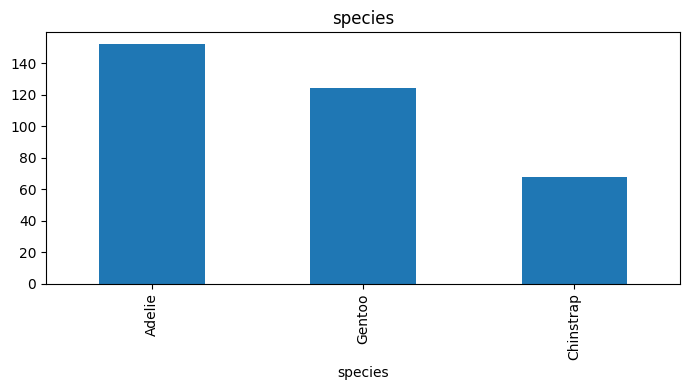

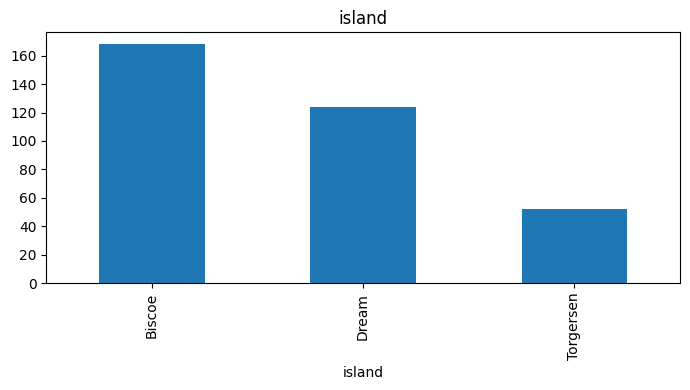

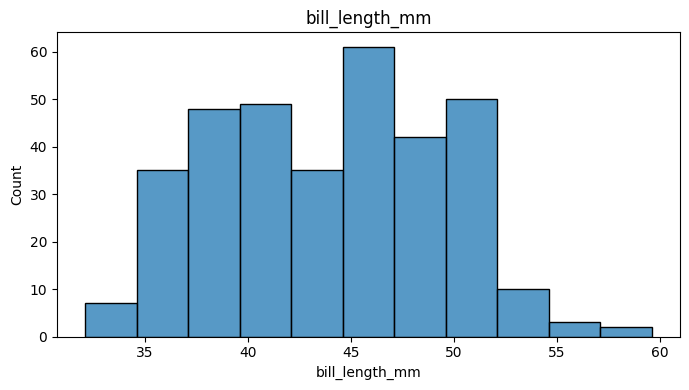

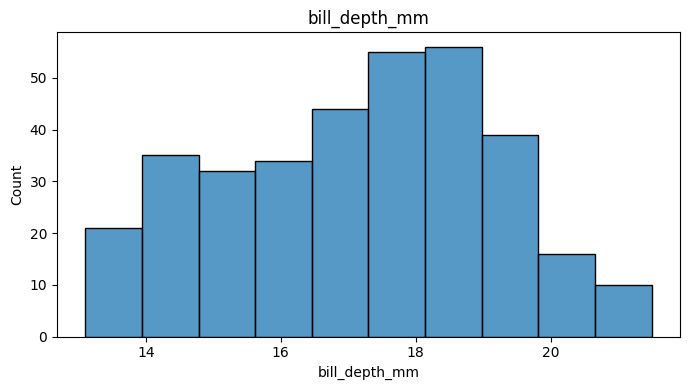

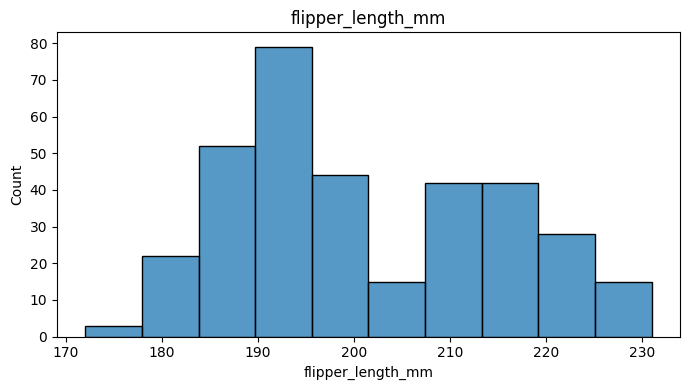

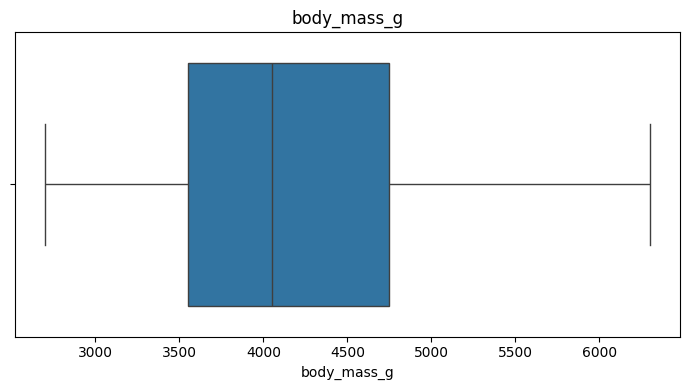

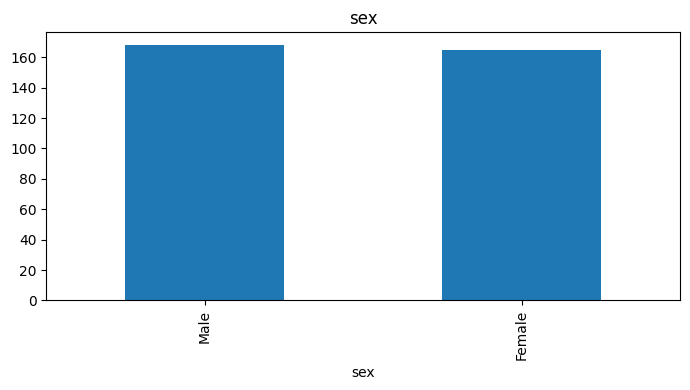

In [1892]:
#Creamos la función para que nos devuelva gráfico por columna:


def explorar_columnas(df):
    for columna in df.columns:
        datos = df[columna].dropna()
        plt.figure(figsize=(7, 4))

        if columna == "body_mass_g":
            sns.boxplot(x=datos)
        elif pd.api.types.is_numeric_dtype(datos):
            sns.histplot(x=datos)
        else:
            datos.value_counts().plot.bar()

        plt.title(columna)
        plt.tight_layout()
        plt.savefig(f"{columna}.png")
        plt.show()
        plt.close()

explorar_columnas(penguins)

He creado una función que recorre las siete columnas del dataset penguins y genera un gráfico para cada una. Para la masa corporal he usado un diagrama de caja, que permite ver la mediana y la dispersión. Para las tres medidas del pico y la aleta he usado histogramas, que muestran cómo se distribuyen los valores. Para la especie, la isla y el sexo he usado gráficos de barras, que muestran cuántos registros hay en cada categoría. La función omite los valores nulos al dibujar, muestra los gráficos en Colab y guarda cada uno como un archivo PNG con el nombre de su columna.

# NIVELL 3 Exercici 2 Optimització de rutes (problema aplicat)

 L'empresa no disposa d'un control fiable del quilometratge dels desplaçaments dels seus treballadors. Abans d'implementar un sistema avançat, es vol fer una prova pilot amb treballadors ubicats a Espanya.

In [1893]:
#Cargamos el archivo, quitando "Las Palmas de Gran Canaria" i "Palma":

ruta_distancias = "/content/drive/MyDrive/Colab Notebooks/matriu_distancies.xlsx"


matriu_distancies = pd.read_excel(ruta_distancias, header=0, index_col=0)
ciudades_a_quitar = ["Las Palmas de Gran Canaria", "Palma"]
matriu_distancies = matriu_distancies.drop(
    index=ciudades_a_quitar,
    columns=ciudades_a_quitar
)

display(matriu_distancies.head())

,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0
Málaga,770.0,468.0,158.0,628.0,NaN,323.0,739.0,391.0,133.0,549.0,716.0,766.0,763.0


In [1894]:
#Creamos la función:

def calcular_ruta(ciudad_origen, ciudad_destino):

  if ciudad_origen not in matriu_distancies.index:
        raise ValueError(f"La ciudad de origen '{ciudad_origen}' no está en la matriz.")

  if ciudad_destino not in matriu_distancies.columns:
        raise ValueError(f"La ciudad de destino '{ciudad_destino}' no está en la matriz.")
  ciudad_actual = ciudad_origen
  ruta = [ciudad_actual]
  distancia_total = 0
  while ciudad_actual != ciudad_destino:
        distancias = matriu_distancies.loc[ciudad_actual]
        distancias = distancias.drop(ruta)
        siguiente_ciudad = distancias.idxmin()
        ruta.append(siguiente_ciudad)
        ciudad_actual = siguiente_ciudad
        distancia_total += distancias[siguiente_ciudad]

  print("Ruta:", " → ".join(ruta))
  print(f"Distancia total de la ruta: {distancia_total:g} km")

  return ruta, distancia_total

In [1895]:
#Llamamos a la función:

calcular_ruta("Barcelona", "Vigo");

Ruta: Barcelona → Hospitalet de Llobregat → Zaragoza → Valencia → Alicante → Murcia → Córdoba → Sevilla → Málaga → Valladolid → Gijón → Bilbao → Vigo
Distancia total de la ruta: 2778 km


He creado la función `calcular_ruta` para construir un recorrido a partir de una ciudad de origen y otra de destino. En cada paso, la función consulta la matriz de distancias, elige la ciudad más cercana a la actual entre las que aún no ha visitado y suma los kilómetros de ese tramo. Según la matriz, la distancia directa entre **Barcelona y Vigo es de 908 km**, mientras que la ruta calculada suma **2.778 km**.

La diferencia se debe a que la función elige el tramo más corto en cada paso sin evaluar la distancia total hasta Vigo. Por ejemplo, su primera parada es Hospitalet de Llobregat, a solo 7 km de Barcelona.